# Examen Parcial: Predicción de Desnutrición Infantil en Ecuador

**Maestría en Ciencia de Datos**

**Autor:** Carolina Benavides

**Asignatura:** Fundamentos de Inteligencia Artificial

**Proyecto:** Competición de Desnutrición Infantil de Ecuador (IISEM2026 MCD)

## Objetivo

Desarrollar y evaluar modelos de aprendizaje automático capaces de predecir el riesgo de desnutrición en niños menores de dos años, utilizando variables antropométricas y sociodemográficas.

Se compararán diferentes algoritmos de clasificación, aplicando técnicas de limpieza de datos, ingeniería de características, validación cruzada y optimización de hiperparámetros.

**Variable objetivo:** `alerta_desnutricion`

- **Clase 0:** Niño sin riesgo de desnutrición.
- **Clase 1:** Niño en riesgo de desnutrición.

**Métrica de evaluación:** Accuracy (exactitud).

In [2]:
import pandas as pd
import numpy as np

print("Bibliotecas importadas correctamente")
print("Versión de Pandas:", pd.__version__)
print("Versión de NumPy:", np.__version__)

Bibliotecas importadas correctamente
Versión de Pandas: 3.1.0
Versión de NumPy: 2.5.4


## 1. Configuración del entorno y reproducibilidad

Se establecen las bibliotecas y los parámetros generales necesarios para desarrollar los experimentos de aprendizaje automático.

Se utilizará una semilla aleatoria fija para facilitar la reproducción de los resultados y mantener condiciones consistentes durante la comparación de modelos.

In [3]:
# Configuración general del proyecto

import sys
import random
import sklearn
import matplotlib
import seaborn

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("CONFIGURACIÓN DEL PROYECTO")
print("--------------------------")
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", seaborn.__version__)
print("Semilla aleatoria:", SEED)


CONFIGURACIÓN DEL PROYECTO
--------------------------
Python: 3.12.10
Pandas: 3.1.0
NumPy: 2.5.4
Scikit-learn: 1.9.1
Matplotlib: 3.11.2
Seaborn: 0.13.2
Semilla aleatoria: 42


In [4]:
from pathlib import Path

# Ubicación de los archivos del proyecto
DATA_DIR = Path.cwd()

# Lectura de los cuatro archivos CSV
X_train = pd.read_csv(DATA_DIR / "X_train_Kaggle.csv")
y_train = pd.read_csv(DATA_DIR / "y_train_Kaggle.csv")
X_test = pd.read_csv(DATA_DIR / "X_test_Kaggle.csv")
sample_submission = pd.read_csv(
    DATA_DIR / "sample_submission_malnutrition.csv"
)

# Verificación de las dimensiones
print("DIMENSIONES DE LOS ARCHIVOS")
print("-" * 45)
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("sample_submission:", sample_submission.shape)

# Verificación de las columnas
print("\nCOLUMNAS DE LOS ARCHIVOS")
print("-" * 45)
print("X_train:", X_train.columns.tolist())
print("y_train:", y_train.columns.tolist())
print("X_test:", X_test.columns.tolist())
print("sample_submission:", sample_submission.columns.tolist())

# Comprobaciones básicas de consistencia
assert len(X_train) == len(y_train), \
    "Error: entrenamiento y etiquetas tienen distinta cantidad de filas."

assert len(X_test) == len(sample_submission), \
    "Error: prueba y archivo de ejemplo tienen distinta cantidad de filas."

assert X_train.columns.tolist() == X_test.columns.tolist(), \
    "Error: las columnas de entrenamiento y prueba son distintas."

print("\nVerificaciones básicas completadas correctamente.")


DIMENSIONES DE LOS ARCHIVOS
---------------------------------------------
X_train: (70000, 6)
y_train: (70000, 1)
X_test: (30000, 6)
sample_submission: (30000, 2)

COLUMNAS DE LOS ARCHIVOS
---------------------------------------------
X_train: ['edad_meses', 'sexo', 'region', 'nivel_educacion_madre', 'peso_kg', 'talla_cm']
y_train: ['alerta_desnutricion']
X_test: ['edad_meses', 'sexo', 'region', 'nivel_educacion_madre', 'peso_kg', 'talla_cm']
sample_submission: ['ID', 'alerta_desnutricion']

Verificaciones básicas completadas correctamente.


## 3. Análisis exploratorio de datos (EDA)


In [5]:
# 3.1. INSPECCIÓN INICIAL DEL CONJUNTO DE DATOS

print("PRIMEROS 5 REGISTROS DEL ENTRENAMIENTO")
display(X_train.head())

print("\nTIPOS DE DATOS Y VALORES NO NULOS")
X_train.info()

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(X_train.describe(include="all").T)

print("\nPRIMERAS 5 ETIQUETAS DE LA VARIABLE OBJETIVO")
display(y_train.head())


PRIMEROS 5 REGISTROS DEL ENTRENAMIENTO


,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm
0,0,F,Costa,Secundaria,2.243466,47.340072
1,11,M,Insular,Secundaria,6.157203,67.525274
2,22,M,Costa,Superior,9.781251,86.664662
3,4,F,Sierra,Primaria,2.972311,61.071857
4,-4,F,Costa,Primaria,NaN,50.898250



TIPOS DE DATOS Y VALORES NO NULOS
<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad_meses             70000 non-null  int64  
 1   sexo                   70000 non-null  str    
 2   region                 70000 non-null  str    
 3   nivel_educacion_madre  70000 non-null  str    
 4   peso_kg                66531 non-null  float64
 5   talla_cm               62951 non-null  float64
dtypes: float64(2), int64(1), str(3)
memory usage: 3.2 MB

ESTADÍSTICAS DESCRIPTIVAS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad_meses,70000.0,NaN,NaN,NaN,11.459457,8.252734,-12.0,5.0,11.0,18.0,29.0
sexo,70000,2,F,35185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,70000,4,Amazonía,17606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nivel_educacion_madre,70000,4,Secundaria,31488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
peso_kg,66531.0,NaN,NaN,NaN,6.879973,4.648722,-0.814205,4.500895,6.523145,8.548997,59.976104
talla_cm,62951.0,NaN,NaN,NaN,67.480033,11.937076,34.904595,57.442414,67.38153,77.444691,98.213648



PRIMERAS 5 ETIQUETAS DE LA VARIABLE OBJETIVO


,alerta_desnutricion
0,0
1,0
2,0
3,0
4,0


In [6]:
# 3.2. EVALUACIÓN DE LA CALIDAD DE LOS DATOS

# 1. Análisis de valores faltantes
calidad_datos = pd.DataFrame({
    "Variable": X_train.columns,
    "Valores_faltantes": X_train.isnull().sum().values,
    "Porcentaje_faltante": (
        X_train.isnull().mean().values * 100
    ).round(2)
})

print("VALORES FALTANTES POR VARIABLE")
display(calidad_datos)

# 2. Análisis de registros duplicados
duplicados = X_train.duplicated().sum()

print("\nREGISTROS DUPLICADOS:", duplicados)

# 3. Identificación de edades fuera del rango esperado
edades_invalidas = (
    (X_train["edad_meses"] < 0) |
    (X_train["edad_meses"] >= 24)
).sum()

print("\nEDADES FUERA DEL RANGO DE 0 A 23 MESES:",
      edades_invalidas)

# 4. Identificación de pesos y tallas no positivos
pesos_invalidos = (X_train["peso_kg"] <= 0).sum()
tallas_invalidas = (X_train["talla_cm"] <= 0).sum()

print("\nPESOS MENORES O IGUALES A CERO:",
      pesos_invalidos)

print("TALLAS MENORES O IGUALES A CERO:",
      tallas_invalidas)

# 5. Verificación de categorías
for columna in ["sexo", "region", "nivel_educacion_madre"]:
    print(f"\nCATEGORÍAS DE {columna}:")
    print(X_train[columna].value_counts(dropna=False))


VALORES FALTANTES POR VARIABLE


,Variable,Valores_faltantes,Porcentaje_faltante
0,edad_meses,0,0.00
1,sexo,0,0.00
2,region,0,0.00
3,nivel_educacion_madre,0,0.00
4,peso_kg,3469,4.96
5,talla_cm,7049,10.07



REGISTROS DUPLICADOS: 100

EDADES FUERA DEL RANGO DE 0 A 23 MESES: 7713

PESOS MENORES O IGUALES A CERO: 11
TALLAS MENORES O IGUALES A CERO: 0

CATEGORÍAS DE sexo:
sexo
F    35185
M    34815
Name: count, dtype: int64

CATEGORÍAS DE region:
region
Amazonía    17606
Costa       17534
Insular     17497
Sierra      17363
Name: count, dtype: int64

CATEGORÍAS DE nivel_educacion_madre:
nivel_educacion_madre
Secundaria         31488
Primaria           24584
Superior           10491
Sin escolaridad     3437
Name: count, dtype: int64


DISTRIBUCIÓN DE LA VARIABLE OBJETIVO


,Cantidad,Porcentaje (%)
alerta_desnutricion,,
0,62991,89.99
1,7009,10.01



Accuracy de referencia: 0.8999
Accuracy de referencia (%): 89.99%


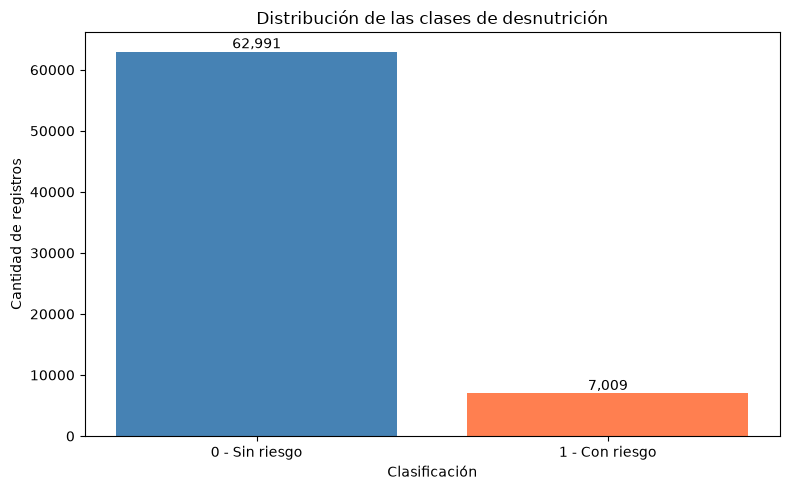

In [7]:
# 3.3. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
# ============================================================

import matplotlib.pyplot as plt

# Seleccionar la variable que queremos predecir
target = y_train["alerta_desnutricion"]

# Calcular cantidades y porcentajes por clase
conteo_clases = target.value_counts().sort_index()
porcentaje_clases = (
    target.value_counts(normalize=True).sort_index() * 100
)

distribucion = pd.DataFrame({
    "Cantidad": conteo_clases,
    "Porcentaje (%)": porcentaje_clases.round(2)
})

print("DISTRIBUCIÓN DE LA VARIABLE OBJETIVO")
display(distribucion)

# Calcular el Accuracy de referencia
accuracy_base = conteo_clases.max() / len(target)

print(f"\nAccuracy de referencia: {accuracy_base:.4f}")
print(f"Accuracy de referencia (%): {accuracy_base * 100:.2f}%")

# Visualización gráfica
fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    ["0 - Sin riesgo", "1 - Con riesgo"],
    conteo_clases.values,
    color=["steelblue", "coral"]
)

ax.set_title("Distribución de las clases de desnutrición")
ax.set_xlabel("Clasificación")
ax.set_ylabel("Cantidad de registros")

for barra, cantidad in zip(barras, conteo_clases.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{cantidad:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


ESTADÍSTICAS DE LAS VARIABLES NUMÉRICAS


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
edad_meses,70000.0,11.459457,8.252734,-12.000000,-5.000000,-1.000000,5.000000,11.000000,18.000000,24.000000,28.000000,29.000000
peso_kg,66531.0,6.879973,4.648722,-0.814205,1.615922,2.580537,4.500895,6.523145,8.548997,10.643235,30.283609,59.976104
talla_cm,62951.0,67.480033,11.937076,34.904595,45.348364,49.059268,57.442414,67.381530,77.444691,86.278021,90.170500,98.213648


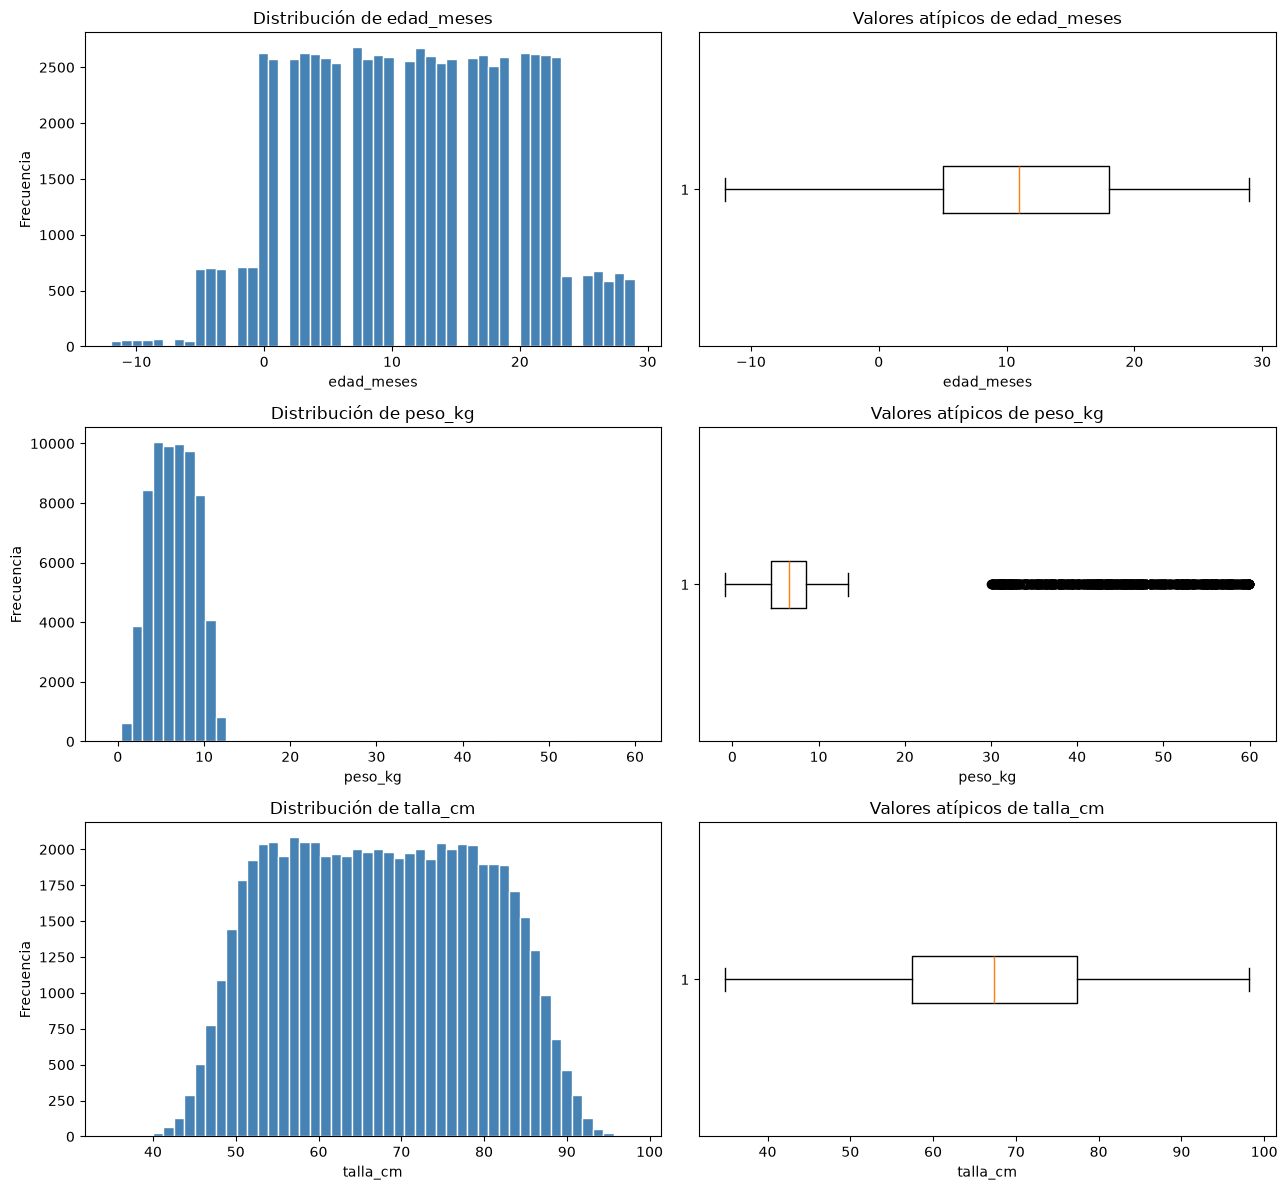

In [8]:
# 3.4. DISTRIBUCIÓN DE VARIABLES NUMÉRICAS
# ============================================================

variables_numericas = ["edad_meses", "peso_kg", "talla_cm"]

# Estadísticas descriptivas detalladas
print("ESTADÍSTICAS DE LAS VARIABLES NUMÉRICAS")

estadisticas = X_train[variables_numericas].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(estadisticas)

# Histogramas y diagramas de caja
fig, axes = plt.subplots(3, 2, figsize=(13, 12))

for i, variable in enumerate(variables_numericas):

    datos = X_train[variable].dropna()

    # Histograma
    axes[i, 0].hist(
        datos,
        bins=50,
        color="steelblue",
        edgecolor="white"
    )
    axes[i, 0].set_title(f"Distribución de {variable}")
    axes[i, 0].set_xlabel(variable)
    axes[i, 0].set_ylabel("Frecuencia")

    # Diagrama de caja
    axes[i, 1].boxplot(
        datos,
        orientation="horizontal"
    )
    axes[i, 1].set_title(f"Valores atípicos de {variable}")
    axes[i, 1].set_xlabel(variable)

plt.tight_layout()
plt.show()


ESTADÍSTICAS NUMÉRICAS POR CLASE


edad_meses              peso_kg              talla_cm  \
                          mean median   std    mean median   std     mean   
alerta_desnutricion                                                         
0                        11.38   11.0  8.29    6.87   6.50  4.69    67.37   
1                        12.15   12.0  7.91    6.97   6.68  4.22    68.48   

                                   
                    median    std  
alerta_desnutricion                
0                    67.27  11.96  
1                    68.37  11.67

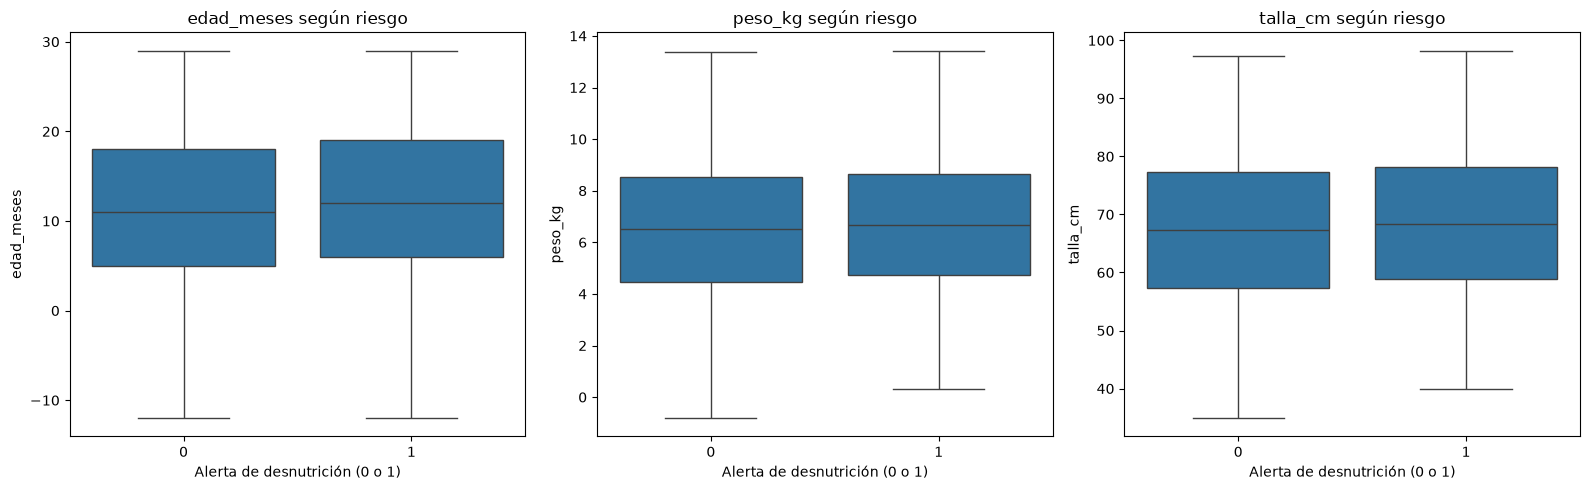


TASA DE RIESGO SEGÚN SEXO


,cantidad,casos_riesgo,tasa_riesgo
sexo,,,
F,35185,3531,10.04
M,34815,3478,9.99



TASA DE RIESGO SEGÚN REGION


,cantidad,casos_riesgo,tasa_riesgo
region,,,
Sierra,17363,2250,12.96
Insular,17497,2246,12.84
Costa,17534,2194,12.51
Amazonía,17606,319,1.81



TASA DE RIESGO SEGÚN NIVEL_EDUCACION_MADRE


,cantidad,casos_riesgo,tasa_riesgo
nivel_educacion_madre,,,
Primaria,24584,2604,10.59
Secundaria,31488,3313,10.52
Superior,10491,1089,10.38
Sin escolaridad,3437,3,0.09


In [10]:
# 3.5. RELACIÓN ENTRE VARIABLES Y RIESGO DE DESNUTRICIÓN

import seaborn as sns

# Crear una copia temporal para el análisis
datos_eda = X_train.copy()

# Incorporar la variable objetivo
datos_eda["alerta_desnutricion"] = target.to_numpy()

# Comparar estadísticas numéricas según la clase
print("ESTADÍSTICAS NUMÉRICAS POR CLASE")
display(
    datos_eda.groupby("alerta_desnutricion")[
        ["edad_meses", "peso_kg", "talla_cm"]
    ].agg(["mean", "median", "std"]).round(2)
)

# Visualizar las variables numéricas según el riesgo
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, variable in enumerate(variables_numericas):
    sns.boxplot(
        data=datos_eda,
        x="alerta_desnutricion",
        y=variable,
        ax=axes[i],
        showfliers=False
    )

    axes[i].set_title(f"{variable} según riesgo")
    axes[i].set_xlabel("Alerta de desnutrición (0 o 1)")
    axes[i].set_ylabel(variable)

plt.tight_layout()
plt.show()

# Analizar tasas de riesgo según variables categóricas
variables_categoricas = [
    "sexo",
    "region",
    "nivel_educacion_madre"
]

for variable in variables_categoricas:
    print(f"\nTASA DE RIESGO SEGÚN {variable.upper()}")

    tabla_riesgo = datos_eda.groupby(variable).agg(
        cantidad=("alerta_desnutricion", "size"),
        casos_riesgo=("alerta_desnutricion", "sum"),
        tasa_riesgo=("alerta_desnutricion", "mean")
    )

    tabla_riesgo["tasa_riesgo"] = (
        tabla_riesgo["tasa_riesgo"] * 100
    ).round(2)

    display(tabla_riesgo.sort_values(
        "tasa_riesgo",
        ascending=False
    ))


MATRIZ DE CORRELACIONES


,edad_meses,peso_kg,talla_cm,alerta_desnutricion
edad_meses,1.000,0.468,0.920,0.028
peso_kg,0.468,1.000,0.463,0.007
talla_cm,0.920,0.463,1.000,0.028
alerta_desnutricion,0.028,0.007,0.028,1.000


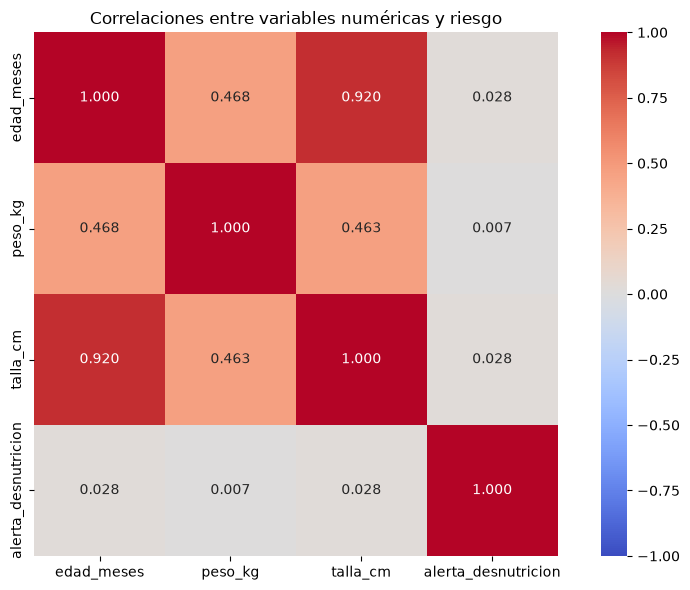


CORRELACIÓN CON LA VARIABLE OBJETIVO


,Correlación con riesgo
edad_meses,0.0281
talla_cm,0.0280
peso_kg,0.0066


In [11]:
# 3.6. ANÁLISIS DE CORRELACIONES

# Seleccionar únicamente variables numéricas
columnas_correlacion = [
    "edad_meses",
    "peso_kg",
    "talla_cm",
    "alerta_desnutricion"
]

# Calcular la matriz de correlaciones
matriz_correlacion = datos_eda[
    columnas_correlacion
].corr(method="pearson")

print("MATRIZ DE CORRELACIONES")
display(matriz_correlacion.round(3))

# Crear mapa de calor
plt.figure(figsize=(9, 6))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlaciones entre variables numéricas y riesgo")
plt.tight_layout()
plt.show()

# Correlación individual con la variable objetivo
print("\nCORRELACIÓN CON LA VARIABLE OBJETIVO")

correlacion_objetivo = (
    matriz_correlacion["alerta_desnutricion"]
    .drop("alerta_desnutricion")
    .sort_values(key=abs, ascending=False)
)

display(correlacion_objetivo.to_frame(
    name="Correlación con riesgo"
).round(4))


## 4. Diseño de la estrategia de validación


In [12]:
# 4.1. DIVISIÓN DE ENTRENAMIENTO Y EVALUACIÓN INTERNA

from sklearn.model_selection import train_test_split

# Variables predictoras y variable objetivo
X = X_train.copy()
y = y_train["alerta_desnutricion"].copy()

# Dividir los datos conservando la proporción de clases
X_desarrollo, X_reserva, y_desarrollo, y_reserva = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Verificar las dimensiones
print("DIVISIÓN DE LOS DATOS")
print("-" * 45)
print("Datos de desarrollo:", X_desarrollo.shape)
print("Etiquetas de desarrollo:", y_desarrollo.shape)
print("Datos de reserva:", X_reserva.shape)
print("Etiquetas de reserva:", y_reserva.shape)

# Verificar la distribución de las clases
print("\nDISTRIBUCIÓN DE CLASES (%)")
distribucion_particiones = pd.DataFrame({
    "Conjunto completo": y.value_counts(normalize=True) * 100,
    "Desarrollo": y_desarrollo.value_counts(normalize=True) * 100,
    "Reserva": y_reserva.value_counts(normalize=True) * 100
}).round(2)

display(distribucion_particiones)

# Comprobar que las particiones no comparten índices
assert set(X_desarrollo.index).isdisjoint(set(X_reserva.index)), \
    "Error: existen índices compartidos entre particiones."

print("\nSeparación de datos completada correctamente.")


DIVISIÓN DE LOS DATOS
---------------------------------------------
Datos de desarrollo: (56000, 6)
Etiquetas de desarrollo: (56000,)
Datos de reserva: (14000, 6)
Etiquetas de reserva: (14000,)

DISTRIBUCIÓN DE CLASES (%)


,Conjunto completo,Desarrollo,Reserva
alerta_desnutricion,,,
0,89.99,89.99,89.99
1,10.01,10.01,10.01



Separación de datos completada correctamente.


In [13]:
# 4.2. VERIFICACIÓN DE DUPLICADOS ENTRE PARTICIONES

# Características duplicadas dentro de cada partición
duplicados_desarrollo = X_desarrollo.duplicated().sum()
duplicados_reserva = X_reserva.duplicated().sum()

print("DUPLICADOS DENTRO DE CADA PARTICIÓN")
print("Desarrollo:", duplicados_desarrollo)
print("Reserva:", duplicados_reserva)

# Buscar registros idénticos entre desarrollo y reserva
columnas = X_desarrollo.columns.tolist()

coincidencias = X_reserva.merge(
    X_desarrollo.drop_duplicates(),
    on=columnas,
    how="inner"
)

print("\nREGISTROS DE RESERVA CON COINCIDENCIAS EN DESARROLLO")
print("Coincidencias:", len(coincidencias))

# Identificar características asociadas a etiquetas distintas
datos_etiquetados = X_train.copy()
datos_etiquetados["alerta_desnutricion"] = y.to_numpy()

conflictos = (
    datos_etiquetados
    .groupby(columnas, dropna=False)["alerta_desnutricion"]
    .nunique()
)

grupos_conflictivos = (conflictos > 1).sum()

print("\nGRUPOS DE CARACTERÍSTICAS CON ETIQUETAS CONTRADICTORIAS")
print("Grupos encontrados:", grupos_conflictivos)

print("\nDiagnóstico de duplicados completado.")


DUPLICADOS DENTRO DE CADA PARTICIÓN
Desarrollo: 73
Reserva: 1

REGISTROS DE RESERVA CON COINCIDENCIAS EN DESARROLLO
Coincidencias: 27

GRUPOS DE CARACTERÍSTICAS CON ETIQUETAS CONTRADICTORIAS
Grupos encontrados: 20

Diagnóstico de duplicados completado.


In [14]:
# 4.3. VALIDACIÓN ALTERNATIVA SIN DUPLICADOS CRUZADOS

from sklearn.model_selection import GroupShuffleSplit

# Construir identificadores de grupos a partir de las características
grupos = pd.util.hash_pandas_object(
    X_train,
    index=False
)

# Crear una división por grupos
divisor_grupos = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

indices_desarrollo, indices_reserva = next(
    divisor_grupos.split(X_train, y, groups=grupos)
)

# Crear los conjuntos de datos alternativos
X_desarrollo_grupos = X_train.iloc[indices_desarrollo].copy()
X_reserva_grupos = X_train.iloc[indices_reserva].copy()

y_desarrollo_grupos = y.iloc[indices_desarrollo].copy()
y_reserva_grupos = y.iloc[indices_reserva].copy()

# Verificar que no existan grupos compartidos
grupos_desarrollo = set(grupos.iloc[indices_desarrollo])
grupos_reserva = set(grupos.iloc[indices_reserva])

assert grupos_desarrollo.isdisjoint(grupos_reserva), \
    "Error: existen grupos compartidos."

# Mostrar resultados
print("DIVISIÓN ALTERNATIVA POR GRUPOS")
print("-" * 45)

print("Registros de desarrollo:", len(X_desarrollo_grupos))
print("Registros de reserva:", len(X_reserva_grupos))

print("\nDISTRIBUCIÓN DE CLASES (%)")

distribucion_grupos = pd.DataFrame({
    "Desarrollo": (
        y_desarrollo_grupos.value_counts(normalize=True) * 100
    ),
    "Reserva": (
        y_reserva_grupos.value_counts(normalize=True) * 100
    )
}).round(2)

display(distribucion_grupos)

print("\nVerificación: ningún grupo compartido entre particiones.")


DIVISIÓN ALTERNATIVA POR GRUPOS
---------------------------------------------
Registros de desarrollo: 56002
Registros de reserva: 13998

DISTRIBUCIÓN DE CLASES (%)


,Desarrollo,Reserva
alerta_desnutricion,,
0,89.99,89.98
1,10.01,10.02



Verificación: ningún grupo compartido entre particiones.


In [15]:
# 4.4. DEFINICIÓN DE LOS CONJUNTOS DE MODELADO

# Conjuntos que utilizaremos para entrenar y comparar modelos
X_dev = X_desarrollo_grupos.copy()
y_dev = y_desarrollo_grupos.copy()

# Conjuntos reservados para la evaluación interna final
X_holdout = X_reserva_grupos.copy()
y_holdout = y_reserva_grupos.copy()

# Identificadores de grupos para validación cruzada
grupos_dev = grupos.iloc[indices_desarrollo].copy()

# Verificar las dimensiones
print("CONJUNTOS DEFINITIVOS DE MODELADO")
print("-" * 45)
print("X_dev:", X_dev.shape)
print("y_dev:", y_dev.shape)
print("X_holdout:", X_holdout.shape)
print("y_holdout:", y_holdout.shape)

# Verificar alineación entre características y etiquetas
assert X_dev.index.equals(y_dev.index)
assert X_holdout.index.equals(y_holdout.index)

# Verificar aislamiento de los grupos
assert set(grupos_dev).isdisjoint(
    set(grupos.iloc[indices_reserva])
)

print("\nConjuntos preparados correctamente.")
print("El conjunto de reserva permanece sin utilizar.")


CONJUNTOS DEFINITIVOS DE MODELADO
---------------------------------------------
X_dev: (56002, 6)
y_dev: (56002,)
X_holdout: (13998, 6)
y_holdout: (13998,)

Conjuntos preparados correctamente.
El conjunto de reserva permanece sin utilizar.


## 5. Preprocesamiento e ingeniería de características


In [17]:
# 5.1. CONSTRUCCIÓN DEL PREPROCESAMIENTO INICIAL

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Variables numéricas y categóricas
columnas_numericas = [
    "edad_meses",
    "peso_kg",
    "talla_cm"
]

columnas_categoricas = [
    "sexo",
    "region",
    "nivel_educacion_madre"
]

# Tratamiento para variables numéricas
pipeline_numerico = Pipeline(steps=[
    ("imputacion", SimpleImputer(
        strategy="median",
        add_indicator=True
    ))
])

# Tratamiento para variables categóricas
pipeline_categorico = Pipeline(steps=[
    ("imputacion", SimpleImputer(
        strategy="most_frequent"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Integrar los tratamientos
preprocesador_base = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_numerico, columnas_numericas),
        ("categoricas", pipeline_categorico, columnas_categoricas)
    ],
    remainder="drop"
)

print("PREPROCESAMIENTO INICIAL CONFIGURADO")
print("Variables numéricas:", columnas_numericas)
print("Variables categóricas:", columnas_categoricas)
print("\nEl preprocesador todavía no se ha ajustado.")
print("Los datos originales permanecen sin modificaciones.")


PREPROCESAMIENTO INICIAL CONFIGURADO
Variables numéricas: ['edad_meses', 'peso_kg', 'talla_cm']
Variables categóricas: ['sexo', 'region', 'nivel_educacion_madre']

El preprocesador todavía no se ha ajustado.
Los datos originales permanecen sin modificaciones.


In [18]:
# 5.2. INGENIERÍA DE CARACTERÍSTICAS

from sklearn.base import BaseEstimator, TransformerMixin

class IngenieriaCaracteristicas(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        datos = X.copy()

        # Indicadores de información faltante
        datos["peso_faltante"] = datos["peso_kg"].isna().astype(int)
        datos["talla_faltante"] = datos["talla_cm"].isna().astype(int)

        # Indicadores de inconsistencias
        datos["edad_fuera_rango"] = (
            (datos["edad_meses"] < 0) |
            (datos["edad_meses"] >= 24)
        ).astype(int)

        datos["peso_no_positivo"] = (
            datos["peso_kg"] <= 0
        ).astype(int)

        # Relaciones antropométricas
        talla_metros = datos["talla_cm"] / 100

        datos["indice_masa_corporal"] = (
            datos["peso_kg"] /
            talla_metros.clip(lower=0.01).pow(2)
        )

        datos["peso_por_talla"] = (
            datos["peso_kg"] /
            datos["talla_cm"].clip(lower=1)
        )

        # Interacciones entre variables
        datos["edad_por_peso"] = (
            datos["edad_meses"] * datos["peso_kg"]
        )

        datos["edad_por_talla"] = (
            datos["edad_meses"] * datos["talla_cm"]
        )

        return datos


# Crear el transformador sin ajustarlo a los datos
ingenieria_caracteristicas = IngenieriaCaracteristicas()

# Definir los nombres de las nuevas características
caracteristicas_nuevas = [
    "peso_faltante",
    "talla_faltante",
    "edad_fuera_rango",
    "peso_no_positivo",
    "indice_masa_corporal",
    "peso_por_talla",
    "edad_por_peso",
    "edad_por_talla"
]

print("INGENIERÍA DE CARACTERÍSTICAS CONFIGURADA")
print("Nuevas características propuestas:")

for caracteristica in caracteristicas_nuevas:
    print("-", caracteristica)

print("\nTransformador preparado sin modificar los datos originales.")


INGENIERÍA DE CARACTERÍSTICAS CONFIGURADA
Nuevas características propuestas:
- peso_faltante
- talla_faltante
- edad_fuera_rango
- peso_no_positivo
- indice_masa_corporal
- peso_por_talla
- edad_por_peso
- edad_por_talla

Transformador preparado sin modificar los datos originales.


In [20]:
# 5.3. INTEGRACIÓN DEL PREPROCESAMIENTO AMPLIADO

from sklearn.base import clone

# Incorporar las nuevas características numéricas
columnas_numericas_ampliadas = (
    columnas_numericas + caracteristicas_nuevas
)

# Crear el preprocesador ampliado
preprocesador_ampliado = ColumnTransformer(
    transformers=[
        (
            "numericas",
            clone(pipeline_numerico),
            columnas_numericas_ampliadas
        ),
        (
            "categoricas",
            clone(pipeline_categorico),
            columnas_categoricas
        )
    ],
    remainder="drop"
)

# Integrar ingeniería y preprocesamiento
pipeline_caracteristicas = Pipeline(steps=[
    ("ingenieria", IngenieriaCaracteristicas()),
    ("preprocesamiento", preprocesador_ampliado)
])

# Verificar la configuración sin ajustar datos
print("ESTRATEGIAS DE PREPROCESAMIENTO")
print("-" * 45)

print("Variables originales:", len(X_dev.columns))
print("Características adicionales:", len(caracteristicas_nuevas))
print(
    "Total de características antes de codificar:",
    len(columnas_numericas_ampliadas) + len(columnas_categoricas)
)

print("\nPreprocesamiento base: configurado")
print("Preprocesamiento ampliado: configurado")

print("\nLos procedimientos todavía no se han ajustado.")
print("El conjunto de reserva permanece sin utilizar.")


ESTRATEGIAS DE PREPROCESAMIENTO
---------------------------------------------
Variables originales: 6
Características adicionales: 8
Total de características antes de codificar: 14

Preprocesamiento base: configurado
Preprocesamiento ampliado: configurado

Los procedimientos todavía no se han ajustado.
El conjunto de reserva permanece sin utilizar.


In [21]:
# 5.4. VERIFICACIÓN TÉCNICA DEL PREPROCESAMIENTO

# Seleccionar una muestra de desarrollo para la prueba
muestra_prueba = X_dev.sample(
    n=min(1000, len(X_dev)),
    random_state=SEED
)

# Crear copias independientes de los procedimientos
prueba_base = clone(preprocesador_base)
prueba_ampliada = clone(pipeline_caracteristicas)

# Aplicar las transformaciones únicamente a la muestra
datos_base = prueba_base.fit_transform(muestra_prueba)
datos_ampliados = prueba_ampliada.fit_transform(muestra_prueba)

# Verificar que todas las características sean numéricas y finitas
assert np.isfinite(datos_base).all(), \
    "Error: el preprocesamiento base contiene valores inválidos."

assert np.isfinite(datos_ampliados).all(), \
    "Error: el preprocesamiento ampliado contiene valores inválidos."

print("VERIFICACIÓN DEL PREPROCESAMIENTO")
print("-" * 45)

print("Registros utilizados:", len(muestra_prueba))
print("Dimensiones del procesamiento base:", datos_base.shape)
print("Dimensiones del procesamiento ampliado:", datos_ampliados.shape)

print("\nValores faltantes en procesamiento base:",
      np.isnan(datos_base).sum())

print("Valores faltantes en procesamiento ampliado:",
      np.isnan(datos_ampliados).sum())

print("\nAmbos procedimientos funcionan correctamente.")
print("No se utilizaron datos del conjunto reservado.")


VERIFICACIÓN DEL PREPROCESAMIENTO
---------------------------------------------
Registros utilizados: 1000
Dimensiones del procesamiento base: (1000, 15)
Dimensiones del procesamiento ampliado: (1000, 27)

Valores faltantes en procesamiento base: 0
Valores faltantes en procesamiento ampliado: 0

Ambos procedimientos funcionan correctamente.
No se utilizaron datos del conjunto reservado.


## 6. Entrenamiento y comparación de modelos predictivos


In [22]:
# 6.1. CONFIGURACIÓN DE LA VALIDACIÓN CRUZADA

from sklearn.model_selection import StratifiedGroupKFold

# Crear cinco particiones de validación
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Comprobar las particiones sin entrenar modelos
resumen_cv = []

for numero, (idx_train, idx_val) in enumerate(
    cv.split(X_dev, y_dev, groups=grupos_dev),
    start=1
):
    grupos_train = set(grupos_dev.iloc[idx_train])
    grupos_val = set(grupos_dev.iloc[idx_val])

    assert grupos_train.isdisjoint(grupos_val), \
        "Error: existen grupos compartidos."

    resumen_cv.append({
        "Partición": numero,
        "Entrenamiento": len(idx_train),
        "Validación": len(idx_val),
        "Riesgo entrenamiento (%)": round(
            y_dev.iloc[idx_train].mean() * 100, 2
        ),
        "Riesgo validación (%)": round(
            y_dev.iloc[idx_val].mean() * 100, 2
        )
    })

print("VERIFICACIÓN DE VALIDACIÓN CRUZADA")
display(pd.DataFrame(resumen_cv))

print("\nCinco particiones configuradas correctamente.")
print("No existen grupos compartidos entre entrenamiento y validación.")


VERIFICACIÓN DE VALIDACIÓN CRUZADA


,Partición,Entrenamiento,Validación,Riesgo entrenamiento (%),Riesgo validación (%)
0,1,44802,11200,10.01,10.01
1,2,44801,11201,10.01,10.01
2,3,44801,11201,10.01,10.01
3,4,44801,11201,10.01,10.02
4,5,44803,11199,10.01,10.01



Cinco particiones configuradas correctamente.
No existen grupos compartidos entre entrenamiento y validación.


In [23]:
# 6.2. MODELO DE REFERENCIA: DUMMY CLASSIFIER

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

# Crear el clasificador de referencia
modelo_dummy = DummyClassifier(
    strategy="most_frequent"
)

# Evaluar con validación cruzada agrupada
resultados_dummy = cross_validate(
    modelo_dummy,
    X_dev,
    y_dev,
    groups=grupos_dev,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

# Extraer los cinco resultados
accuracy_dummy = resultados_dummy["test_score"]

# Guardar los resultados para comparar modelos posteriormente
resultados_modelos = []

resultados_modelos.append({
    "Modelo": "DummyClassifier",
    "Preprocesamiento": "Sin transformación",
    "Accuracy_promedio": accuracy_dummy.mean(),
    "Desviacion_estandar": accuracy_dummy.std(),
    "Accuracy_minimo": accuracy_dummy.min(),
    "Accuracy_maximo": accuracy_dummy.max()
})

print("RESULTADOS DEL MODELO DE REFERENCIA")
print("-" * 45)

for i, puntuacion in enumerate(accuracy_dummy, start=1):
    print(f"Partición {i}: {puntuacion:.4f}")

print(f"\nAccuracy promedio: {accuracy_dummy.mean():.4f}")
print(f"Desviación estándar: {accuracy_dummy.std():.4f}")

print("\nTABLA DE RESULTADOS")
display(pd.DataFrame(resultados_modelos).round(4))


RESULTADOS DEL MODELO DE REFERENCIA
---------------------------------------------
Partición 1: 0.8999
Partición 2: 0.8999
Partición 3: 0.8999
Partición 4: 0.8998
Partición 5: 0.8999

Accuracy promedio: 0.8999
Desviación estándar: 0.0000

TABLA DE RESULTADOS


,Modelo,Preprocesamiento,Accuracy_promedio,Desviacion_estandar,Accuracy_minimo,Accuracy_maximo
0,DummyClassifier,Sin transformación,0.8999,0.0,0.8998,0.8999


In [24]:
# 6.3. MODELO DE REGRESIÓN LOGÍSTICA

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Preprocesamiento numérico con escalado
pipeline_numerico_logistico = Pipeline(steps=[
    ("imputacion", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("escalado", StandardScaler())
])

# Combinar procesamiento numérico y categórico
preprocesador_logistico = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_numerico_logistico, columnas_numericas),
        ("categoricas", clone(pipeline_categorico), columnas_categoricas)
    ]
)

# Construir Pipeline completo
modelo_logistico = Pipeline(steps=[
    ("preprocesamiento", preprocesador_logistico),
    ("modelo", LogisticRegression(
        max_iter=2000,
        random_state=SEED
    ))
])

# Evaluar con la misma validación cruzada agrupada
resultados_logistico = cross_validate(
    modelo_logistico,
    X_dev,
    y_dev,
    groups=grupos_dev,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

accuracy_logistico = resultados_logistico["test_score"]

# Agregar resultados a la tabla comparativa
resultados_modelos.append({
    "Modelo": "Regresión Logística",
    "Preprocesamiento": "Base + escalado",
    "Accuracy_promedio": accuracy_logistico.mean(),
    "Desviacion_estandar": accuracy_logistico.std(),
    "Accuracy_minimo": accuracy_logistico.min(),
    "Accuracy_maximo": accuracy_logistico.max()
})

print("RESULTADOS DE REGRESIÓN LOGÍSTICA")
print("-" * 45)

for i, puntuacion in enumerate(accuracy_logistico, start=1):
    print(f"Partición {i}: {puntuacion:.4f}")

print(f"\nAccuracy promedio: {accuracy_logistico.mean():.4f}")
print(f"Desviación estándar: {accuracy_logistico.std():.4f}")

print("\nCOMPARACIÓN DE MODELOS")
display(
    pd.DataFrame(resultados_modelos)
    .sort_values("Accuracy_promedio", ascending=False)
    .round(4)
)


RESULTADOS DE REGRESIÓN LOGÍSTICA
---------------------------------------------
Partición 1: 0.8999
Partición 2: 0.8999
Partición 3: 0.8999
Partición 4: 0.8998
Partición 5: 0.8999

Accuracy promedio: 0.8999
Desviación estándar: 0.0000

COMPARACIÓN DE MODELOS


,Modelo,Preprocesamiento,Accuracy_promedio,Desviacion_estandar,Accuracy_minimo,Accuracy_maximo
0,DummyClassifier,Sin transformación,0.8999,0.0,0.8998,0.8999
1,Regresión Logística,Base + escalado,0.8999,0.0,0.8998,0.8999


In [25]:
# 6.4. DIAGNÓSTICO DE CLASIFICACIÓN BINARIA

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

from sklearn.model_selection import cross_val_predict

# Predicciones fuera de muestra en las 5 particiones
predicciones_logisticas = cross_val_predict(
    modelo_logistico,
    X_dev,
    y_dev,
    groups=grupos_dev,
    cv=cv,
    method="predict",
    n_jobs=1
)

print("CLASES PREDICHAS POR EL MODELO")
print(pd.Series(predicciones_logisticas).value_counts().sort_index())

print("\nMATRIZ DE CONFUSIÓN")
matriz = confusion_matrix(
    y_dev,
    predicciones_logisticas,
    labels=[0, 1]
)
display(pd.DataFrame(
    matriz,
    index=["Real 0", "Real 1"],
    columns=["Predicho 0", "Predicho 1"]
))

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_dev,
    predicciones_logisticas,
    labels=[0, 1],
    zero_division=0
))

print("Accuracy global fuera de muestra:",
      round(accuracy_score(y_dev, predicciones_logisticas), 4))


CLASES PREDICHAS POR EL MODELO
0    56002
Name: count, dtype: int64

MATRIZ DE CONFUSIÓN


,Predicho 0,Predicho 1
Real 0,50396,0
Real 1,5606,0



REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

           0       0.90      1.00      0.95     50396
           1       0.00      0.00      0.00      5606

    accuracy                           0.90     56002
   macro avg       0.45      0.50      0.47     56002
weighted avg       0.81      0.90      0.85     56002

Accuracy global fuera de muestra: 0.8999


In [26]:
# 6.5. MODELO DE ÁRBOL DE DECISIÓN

from sklearn.tree import DecisionTreeClassifier

# Crear el modelo con preprocesamiento base
modelo_arbol = Pipeline(steps=[
    ("preprocesamiento", clone(preprocesador_base)),
    ("modelo", DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=30,
        random_state=SEED
    ))
])

# Evaluar con validación cruzada agrupada
resultados_arbol = cross_validate(
    modelo_arbol,
    X_dev,
    y_dev,
    groups=grupos_dev,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

accuracy_arbol = resultados_arbol["test_score"]

# Registrar resultados
resultados_modelos.append({
    "Modelo": "Árbol de Decisión",
    "Preprocesamiento": "Base",
    "Accuracy_promedio": accuracy_arbol.mean(),
    "Desviacion_estandar": accuracy_arbol.std(),
    "Accuracy_minimo": accuracy_arbol.min(),
    "Accuracy_maximo": accuracy_arbol.max()
})

print("RESULTADOS DEL ÁRBOL DE DECISIÓN")
print("-" * 45)

for i, puntuacion in enumerate(accuracy_arbol, start=1):
    print(f"Partición {i}: {puntuacion:.4f}")

print(f"\nAccuracy promedio: {accuracy_arbol.mean():.4f}")
print(f"Desviación estándar: {accuracy_arbol.std():.4f}")

print("\nCOMPARACIÓN DE MODELOS")
display(
    pd.DataFrame(resultados_modelos)
    .sort_values("Accuracy_promedio", ascending=False)
    .round(4)
)


RESULTADOS DEL ÁRBOL DE DECISIÓN
---------------------------------------------
Partición 1: 0.8999
Partición 2: 0.8999
Partición 3: 0.8999
Partición 4: 0.8998
Partición 5: 0.8999

Accuracy promedio: 0.8999
Desviación estándar: 0.0000

COMPARACIÓN DE MODELOS


,Modelo,Preprocesamiento,Accuracy_promedio,Desviacion_estandar,Accuracy_minimo,Accuracy_maximo
0,DummyClassifier,Sin transformación,0.8999,0.0,0.8998,0.8999
1,Regresión Logística,Base + escalado,0.8999,0.0,0.8998,0.8999
2,Árbol de Decisión,Base,0.8999,0.0,0.8998,0.8999


In [27]:
# 6.6. DIAGNÓSTICO DEL ÁRBOL DE DECISIÓN

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
from sklearn.model_selection import cross_val_predict

# Predicciones fuera de muestra
predicciones_arbol = cross_val_predict(
    modelo_arbol,
    X_dev,
    y_dev,
    groups=grupos_dev,
    cv=cv,
    method="predict",
    n_jobs=1
)

print("DISTRIBUCIÓN DE PREDICCIONES DEL ÁRBOL")
print(pd.Series(predicciones_arbol).value_counts().sort_index())

print("\nMATRIZ DE CONFUSIÓN")

matriz_arbol = confusion_matrix(
    y_dev,
    predicciones_arbol,
    labels=[0, 1]
)

display(pd.DataFrame(
    matriz_arbol,
    index=["Real 0", "Real 1"],
    columns=["Predicho 0", "Predicho 1"]
))

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_dev,
    predicciones_arbol,
    labels=[0, 1],
    zero_division=0
))

print(
    "\nAccuracy global fuera de muestra:",
    round(accuracy_score(y_dev, predicciones_arbol), 4)
)


DISTRIBUCIÓN DE PREDICCIONES DEL ÁRBOL
0    56002
Name: count, dtype: int64

MATRIZ DE CONFUSIÓN


,Predicho 0,Predicho 1
Real 0,50396,0
Real 1,5606,0



REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

           0       0.90      1.00      0.95     50396
           1       0.00      0.00      0.00      5606

    accuracy                           0.90     56002
   macro avg       0.45      0.50      0.47     56002
weighted avg       0.81      0.90      0.85     56002


Accuracy global fuera de muestra: 0.8999


In [28]:
# 6.7. ÁRBOL CON INGENIERÍA DE CARACTERÍSTICAS

# Construir modelo con características ampliadas
modelo_arbol_ampliado = Pipeline(steps=[
    ("ingenieria", IngenieriaCaracteristicas()),
    ("preprocesamiento", clone(preprocesador_ampliado)),
    ("modelo", DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=10,
        random_state=SEED
    ))
])

# Evaluar mediante validación cruzada agrupada
resultados_arbol_ampliado = cross_validate(
    modelo_arbol_ampliado,
    X_dev,
    y_dev,
    groups=grupos_dev,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

accuracy_arbol_ampliado = resultados_arbol_ampliado["test_score"]

# Registrar resultados
resultados_modelos.append({
    "Modelo": "Árbol de Decisión Ampliado",
    "Preprocesamiento": "Ingeniería de características",
    "Accuracy_promedio": accuracy_arbol_ampliado.mean(),
    "Desviacion_estandar": accuracy_arbol_ampliado.std(),
    "Accuracy_minimo": accuracy_arbol_ampliado.min(),
    "Accuracy_maximo": accuracy_arbol_ampliado.max()
})

print("ÁRBOL DE DECISIÓN CON INGENIERÍA DE CARACTERÍSTICAS")
print("-" * 55)

for i, puntuacion in enumerate(accuracy_arbol_ampliado, start=1):
    print(f"Partición {i}: {puntuacion:.4f}")

print(f"\nAccuracy promedio: {accuracy_arbol_ampliado.mean():.4f}")
print(f"Desviación estándar: {accuracy_arbol_ampliado.std():.4f}")

print("\nCOMPARACIÓN DE TODOS LOS MODELOS")
display(
    pd.DataFrame(resultados_modelos)
    .sort_values("Accuracy_promedio", ascending=False)
    .round(4)
)


ÁRBOL DE DECISIÓN CON INGENIERÍA DE CARACTERÍSTICAS
-------------------------------------------------------
Partición 1: 0.8959
Partición 2: 0.8977
Partición 3: 0.8973
Partición 4: 0.8961
Partición 5: 0.8945

Accuracy promedio: 0.8963
Desviación estándar: 0.0011

COMPARACIÓN DE TODOS LOS MODELOS


,Modelo,Preprocesamiento,Accuracy_promedio,Desviacion_estandar,Accuracy_minimo,Accuracy_maximo
0,DummyClassifier,Sin transformación,0.8999,0.0000,0.8998,0.8999
1,Regresión Logística,Base + escalado,0.8999,0.0000,0.8998,0.8999
2,Árbol de Decisión,Base,0.8999,0.0000,0.8998,0.8999
3,Árbol de Decisión Ampliado,Ingeniería de características,0.8963,0.0011,0.8945,0.8977


In [29]:
# 6.8. MODELO RANDOM FOREST

from sklearn.ensemble import RandomForestClassifier

# Crear Random Forest con preprocesamiento base
modelo_random_forest = Pipeline(steps=[
    ("preprocesamiento", clone(preprocesador_base)),
    ("modelo", RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=10,
        max_features="sqrt",
        random_state=SEED,
        n_jobs=-1
    ))
])

# Evaluar mediante validación cruzada agrupada
resultados_rf = cross_validate(
    modelo_random_forest,
    X_dev,
    y_dev,
    groups=grupos_dev,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

accuracy_rf = resultados_rf["test_score"]

# Guardar resultados comparativos
resultados_modelos.append({
    "Modelo": "Random Forest",
    "Preprocesamiento": "Base",
    "Accuracy_promedio": accuracy_rf.mean(),
    "Desviacion_estandar": accuracy_rf.std(),
    "Accuracy_minimo": accuracy_rf.min(),
    "Accuracy_maximo": accuracy_rf.max()
})

print("RESULTADOS DE RANDOM FOREST")
print("-" * 45)

for i, puntuacion in enumerate(accuracy_rf, start=1):
    print(f"Partición {i}: {puntuacion:.4f}")

print(f"\nAccuracy promedio: {accuracy_rf.mean():.4f}")
print(f"Desviación estándar: {accuracy_rf.std():.4f}")

print("\nCOMPARACIÓN DE TODOS LOS MODELOS")
display(
    pd.DataFrame(resultados_modelos)
    .sort_values("Accuracy_promedio", ascending=False)
    .round(4)
)


RESULTADOS DE RANDOM FOREST
---------------------------------------------
Partición 1: 0.8999
Partición 2: 0.8999
Partición 3: 0.8999
Partición 4: 0.8998
Partición 5: 0.8999

Accuracy promedio: 0.8999
Desviación estándar: 0.0000

COMPARACIÓN DE TODOS LOS MODELOS


,Modelo,Preprocesamiento,Accuracy_promedio,Desviacion_estandar,Accuracy_minimo,Accuracy_maximo
0,DummyClassifier,Sin transformación,0.8999,0.0000,0.8998,0.8999
1,Regresión Logística,Base + escalado,0.8999,0.0000,0.8998,0.8999
2,Árbol de Decisión,Base,0.8999,0.0000,0.8998,0.8999
4,Random Forest,Base,0.8999,0.0000,0.8998,0.8999
3,Árbol de Decisión Ampliado,Ingeniería de características,0.8963,0.0011,0.8945,0.8977


DISTRIBUCIÓN DE PROBABILIDADES


count    56002.000000
mean         0.100087
std          0.059510
min          0.000000
10%          0.012108
25%          0.025395
50%          0.124828
75%          0.143601
90%          0.159766
95%          0.171804
99%          0.201203
max          0.293390
Name: Probabilidad de riesgo, dtype: float64


PROBABILIDADES SEGÚN LA CLASE REAL


,mean,median,min,max
Clase_real,,,,
0,0.0964,0.1227,0.0000,0.2934
1,0.1330,0.1359,0.0015,0.2738



ROC-AUC fuera de muestra: 0.6532


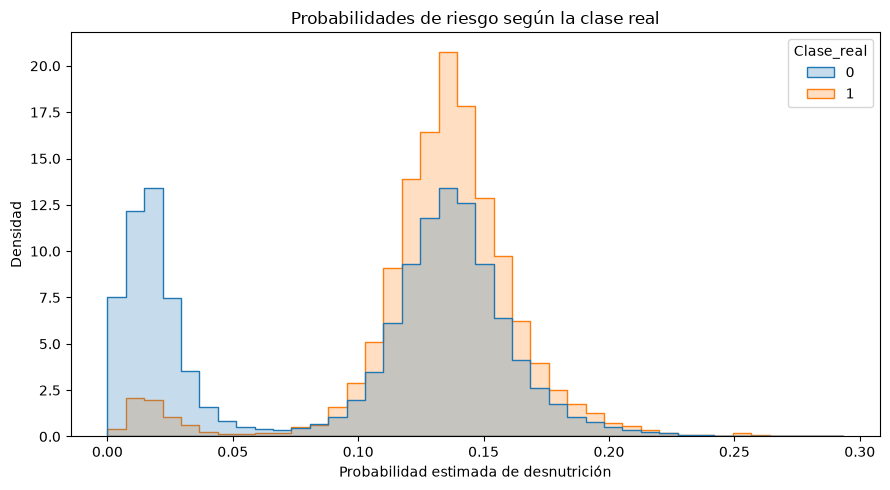

In [30]:
# 6.9. ANÁLISIS DE PROBABILIDADES - RANDOM FOREST

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

# Obtener probabilidades fuera de muestra
probabilidades_rf = cross_val_predict(
    modelo_random_forest,
    X_dev,
    y_dev,
    groups=grupos_dev,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Estadísticas de las probabilidades
print("DISTRIBUCIÓN DE PROBABILIDADES")
display(
    pd.Series(probabilidades_rf, name="Probabilidad de riesgo")
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
)

# Comparar probabilidades según la clase real
comparacion_probabilidades = pd.DataFrame({
    "Clase_real": y_dev.to_numpy(),
    "Probabilidad_riesgo": probabilidades_rf
})

print("\nPROBABILIDADES SEGÚN LA CLASE REAL")
display(
    comparacion_probabilidades.groupby("Clase_real")[
        "Probabilidad_riesgo"
    ].agg(["mean", "median", "min", "max"]).round(4)
)

# Calcular ROC-AUC
auc_rf = roc_auc_score(y_dev, probabilidades_rf)

print(f"\nROC-AUC fuera de muestra: {auc_rf:.4f}")

# Visualización
plt.figure(figsize=(9, 5))

sns.histplot(
    data=comparacion_probabilidades,
    x="Probabilidad_riesgo",
    hue="Clase_real",
    bins=40,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Probabilidades de riesgo según la clase real")
plt.xlabel("Probabilidad estimada de desnutrición")
plt.ylabel("Densidad")
plt.tight_layout()
plt.show()


MEJORES UMBRALES EXPLORATORIOS


,Umbral,Accuracy,Precision_clase_1,Recall_clase_1,F1_clase_1,Predicciones_clase_1
32,0.37,0.8999,0.0,0.0,0.0,0
33,0.38,0.8999,0.0,0.0,0.0,0
34,0.39,0.8999,0.0,0.0,0.0,0
35,0.40,0.8999,0.0,0.0,0.0,0
36,0.41,0.8999,0.0,0.0,0.0,0
37,0.42,0.8999,0.0,0.0,0.0,0
38,0.43,0.8999,0.0,0.0,0.0,0
39,0.44,0.8999,0.0,0.0,0.0,0
40,0.45,0.8999,0.0,0.0,0.0,0
25,0.30,0.8999,0.0,0.0,0.0,0



Mejor umbral exploratorio: 0.3
Accuracy exploratorio: 0.8999
Accuracy con umbral 0.50: 0.8999


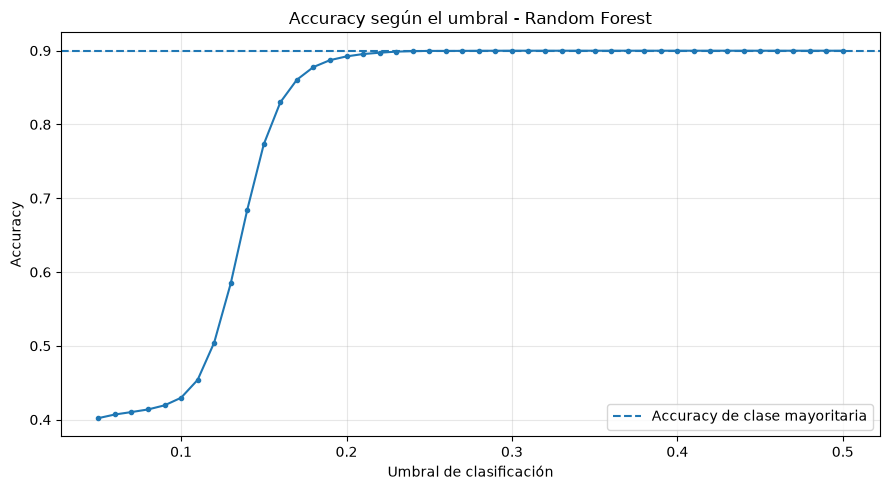

In [31]:
# 6.10. EXPLORACIÓN DE UMBRALES - RANDOM FOREST

from sklearn.metrics import precision_score, recall_score, f1_score

# Probar diferentes umbrales
umbrales = np.arange(0.05, 0.501, 0.01)

resultados_umbrales = []

for umbral in umbrales:

    predicciones = (
        probabilidades_rf >= umbral
    ).astype(int)

    resultados_umbrales.append({
        "Umbral": round(float(umbral), 3),
        "Accuracy": accuracy_score(y_dev, predicciones),
        "Precision_clase_1": precision_score(
            y_dev, predicciones, zero_division=0
        ),
        "Recall_clase_1": recall_score(
            y_dev, predicciones, zero_division=0
        ),
        "F1_clase_1": f1_score(
            y_dev, predicciones, zero_division=0
        ),
        "Predicciones_clase_1": int(predicciones.sum())
    })

tabla_umbrales = pd.DataFrame(resultados_umbrales)

print("MEJORES UMBRALES EXPLORATORIOS")
display(
    tabla_umbrales.sort_values(
        "Accuracy",
        ascending=False
    ).head(10).round(4)
)

# Mejor umbral exploratorio
mejor_fila = tabla_umbrales.loc[
    tabla_umbrales["Accuracy"].idxmax()
]

print("\nMejor umbral exploratorio:",
      round(mejor_fila["Umbral"], 3))

print("Accuracy exploratorio:",
      round(mejor_fila["Accuracy"], 4))

print("Accuracy con umbral 0.50:",
      round(accuracy_score(
          y_dev,
          (probabilidades_rf >= 0.50).astype(int)
      ), 4))

# Visualizar la relación entre umbral y Accuracy
plt.figure(figsize=(9, 5))

plt.plot(
    tabla_umbrales["Umbral"],
    tabla_umbrales["Accuracy"],
    marker="o",
    markersize=3
)

plt.axhline(
    y_dev.value_counts(normalize=True).max(),
    linestyle="--",
    label="Accuracy de clase mayoritaria"
)

plt.xlabel("Umbral de clasificación")
plt.ylabel("Accuracy")
plt.title("Accuracy según el umbral - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [32]:
# 6.11. MODELO HISTGRADIENTBOOSTING

from sklearn.ensemble import HistGradientBoostingClassifier

# Construir modelo con preprocesamiento base
modelo_histgb = Pipeline(steps=[
    ("preprocesamiento", clone(preprocesador_base)),
    ("modelo", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=1.0,
        random_state=SEED
    ))
])

# Evaluar dos métricas con validación cruzada agrupada
resultados_histgb = cross_validate(
    modelo_histgb,
    X_dev,
    y_dev,
    groups=grupos_dev,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    n_jobs=1
)

accuracy_histgb = resultados_histgb["test_accuracy"]
auc_histgb_cv = resultados_histgb["test_roc_auc"]

# Registrar resultados
resultados_modelos.append({
    "Modelo": "HistGradientBoosting",
    "Preprocesamiento": "Base",
    "Accuracy_promedio": accuracy_histgb.mean(),
    "Desviacion_estandar": accuracy_histgb.std(),
    "Accuracy_minimo": accuracy_histgb.min(),
    "Accuracy_maximo": accuracy_histgb.max()
})

print("RESULTADOS DE HISTGRADIENTBOOSTING")
print("-" * 50)

for i, (acc, auc) in enumerate(
    zip(accuracy_histgb, auc_histgb_cv),
    start=1
):
    print(f"Partición {i}: Accuracy={acc:.4f} | ROC-AUC={auc:.4f}")

print(f"\nAccuracy promedio: {accuracy_histgb.mean():.4f}")
print(f"ROC-AUC promedio: {auc_histgb_cv.mean():.4f}")
print(f"Desviación de Accuracy: {accuracy_histgb.std():.4f}")

print("\nCOMPARACIÓN DE MODELOS")
display(
    pd.DataFrame(resultados_modelos)
    .sort_values("Accuracy_promedio", ascending=False)
    .round(4)
)


RESULTADOS DE HISTGRADIENTBOOSTING
--------------------------------------------------
Partición 1: Accuracy=0.8999 | ROC-AUC=0.6484
Partición 2: Accuracy=0.8999 | ROC-AUC=0.6473
Partición 3: Accuracy=0.8999 | ROC-AUC=0.6535
Partición 4: Accuracy=0.8998 | ROC-AUC=0.6542
Partición 5: Accuracy=0.8999 | ROC-AUC=0.6486

Accuracy promedio: 0.8999
ROC-AUC promedio: 0.6504
Desviación de Accuracy: 0.0000

COMPARACIÓN DE MODELOS


,Modelo,Preprocesamiento,Accuracy_promedio,Desviacion_estandar,Accuracy_minimo,Accuracy_maximo
0,DummyClassifier,Sin transformación,0.8999,0.0000,0.8998,0.8999
1,Regresión Logística,Base + escalado,0.8999,0.0000,0.8998,0.8999
2,Árbol de Decisión,Base,0.8999,0.0000,0.8998,0.8999
4,Random Forest,Base,0.8999,0.0000,0.8998,0.8999
5,HistGradientBoosting,Base,0.8999,0.0000,0.8998,0.8999
3,Árbol de Decisión Ampliado,Ingeniería de características,0.8963,0.0011,0.8945,0.8977


RIESGO SEGÚN REGIÓN Y EDUCACIÓN MATERNA


,region,nivel_educacion_madre,registros,casos_riesgo,tasa_riesgo
12,Sierra,Primaria,4914,697,14.18
9,Insular,Secundaria,6303,877,13.91
15,Sierra,Superior,2034,283,13.91
13,Sierra,Secundaria,6235,833,13.36
4,Costa,Primaria,4956,657,13.26
7,Costa,Superior,2117,276,13.04
11,Insular,Superior,2156,281,13.03
8,Insular,Primaria,4904,637,12.99
5,Costa,Secundaria,6264,813,12.98
1,Amazonía,Secundaria,6437,122,1.90


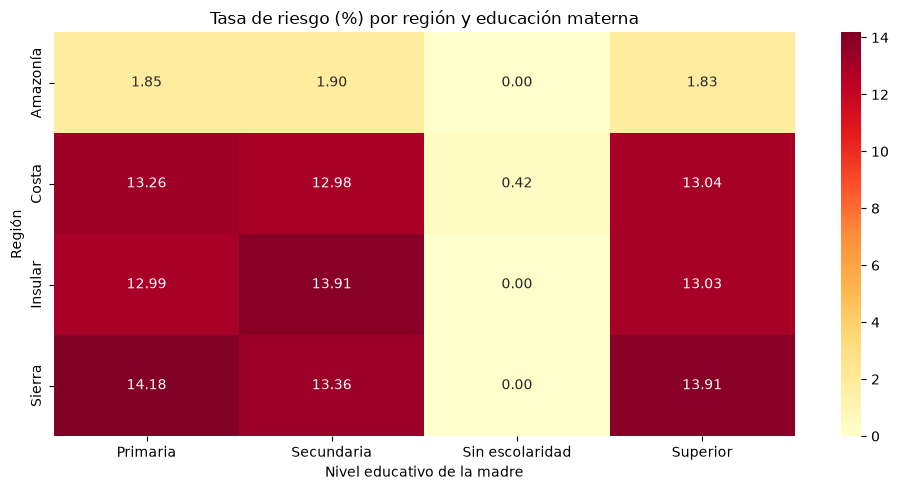

In [33]:
# 6.12. INTERACCIONES ENTRE VARIABLES CATEGÓRICAS

# Crear copia de los datos de desarrollo
datos_interacciones = X_dev.copy()
datos_interacciones["alerta_desnutricion"] = y_dev.to_numpy()

# Calcular cantidad y tasa de riesgo por combinación
tabla_interacciones = (
    datos_interacciones
    .groupby(["region", "nivel_educacion_madre"])
    .agg(
        registros=("alerta_desnutricion", "size"),
        casos_riesgo=("alerta_desnutricion", "sum"),
        tasa_riesgo=("alerta_desnutricion", "mean")
    )
    .reset_index()
)

tabla_interacciones["tasa_riesgo"] = (
    tabla_interacciones["tasa_riesgo"] * 100
).round(2)

print("RIESGO SEGÚN REGIÓN Y EDUCACIÓN MATERNA")

display(
    tabla_interacciones.sort_values(
        "tasa_riesgo",
        ascending=False
    )
)

# Construir tabla para visualización
matriz_riesgo = tabla_interacciones.pivot(
    index="region",
    columns="nivel_educacion_madre",
    values="tasa_riesgo"
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    matriz_riesgo,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)

plt.title("Tasa de riesgo (%) por región y educación materna")
plt.xlabel("Nivel educativo de la madre")
plt.ylabel("Región")
plt.tight_layout()
plt.show()


In [34]:
# 6.13. VERIFICACIÓN DE BIBLIOTECAS AVANZADAS

import catboost
import xgboost
import lightgbm

from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

print("BIBLIOTECAS AVANZADAS DISPONIBLES")
print("-" * 45)

print("CatBoost:", catboost.__version__)
print("XGBoost:", xgboost.__version__)
print("LightGBM:", lightgbm.__version__)

print("\nImportaciones realizadas correctamente.")
print("Los modelos todavía no han sido entrenados.")


BIBLIOTECAS AVANZADAS DISPONIBLES
---------------------------------------------
CatBoost: 1.2.10
XGBoost: 3.4.1
LightGBM: 4.7.0

Importaciones realizadas correctamente.
Los modelos todavía no han sido entrenados.


In [36]:
# 6.14. MODELO CATBOOST - VALIDACIÓN CRUZADA AGRUPADA

from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# Variables categóricas
categoricas_catboost = [
    "sexo",
    "region",
    "nivel_educacion_madre"
]

# Configuración reproducible de CatBoost
parametros_catboost = {
    "iterations": 400,
    "depth": 6,
    "learning_rate": 0.05,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "cat_features": categoricas_catboost,
    "random_seed": SEED,
    "verbose": False,
    "thread_count": 4,
    "allow_writing_files": False
}

accuracy_catboost = []
auc_catboost = []

# Utilizar las mismas cinco particiones agrupadas
for numero, (idx_train, idx_val) in enumerate(
    cv.split(X_dev, y_dev, groups=grupos_dev),
    start=1
):

    X_entrenamiento = X_dev.iloc[idx_train].copy()
    X_validacion = X_dev.iloc[idx_val].copy()

    y_entrenamiento = y_dev.iloc[idx_train]
    y_validacion = y_dev.iloc[idx_val]

    # Crear un modelo independiente para cada partición
    modelo = CatBoostClassifier(**parametros_catboost)

    # Entrenar únicamente con los datos correspondientes
    modelo.fit(X_entrenamiento, y_entrenamiento)

    # Obtener clases binarias y probabilidades
    predicciones = modelo.predict(X_validacion).astype(int).ravel()
    probabilidades = modelo.predict_proba(X_validacion)[:, 1]

    # Calcular métricas
    acc = accuracy_score(y_validacion, predicciones)
    auc = roc_auc_score(y_validacion, probabilidades)

    accuracy_catboost.append(acc)
    auc_catboost.append(auc)

    print(
        f"Partición {numero}: "
        f"Accuracy={acc:.4f} | ROC-AUC={auc:.4f}"
    )

accuracy_catboost = np.array(accuracy_catboost)
auc_catboost = np.array(auc_catboost)

# Registrar resultados
resultados_modelos.append({
    "Modelo": "CatBoost",
    "Preprocesamiento": "Categorías nativas",
    "Accuracy_promedio": accuracy_catboost.mean(),
    "Desviacion_estandar": accuracy_catboost.std(),
    "Accuracy_minimo": accuracy_catboost.min(),
    "Accuracy_maximo": accuracy_catboost.max()
})

print("\nRESULTADOS FINALES DE CATBOOST")
print("-" * 45)
print(f"Accuracy promedio: {accuracy_catboost.mean():.4f}")
print(f"ROC-AUC promedio: {auc_catboost.mean():.4f}")
print(f"Desviación estándar: {accuracy_catboost.std():.4f}")

print("\nCOMPARACIÓN DE MODELOS")

display(
    pd.DataFrame(resultados_modelos)
    .sort_values("Accuracy_promedio", ascending=False)
    .round(4)
)


Partición 1: Accuracy=0.8999 | ROC-AUC=0.6463
Partición 2: Accuracy=0.8999 | ROC-AUC=0.6397
Partición 3: Accuracy=0.8999 | ROC-AUC=0.6518
Partición 4: Accuracy=0.8998 | ROC-AUC=0.6488
Partición 5: Accuracy=0.8999 | ROC-AUC=0.6496

RESULTADOS FINALES DE CATBOOST
---------------------------------------------
Accuracy promedio: 0.8999
ROC-AUC promedio: 0.6472
Desviación estándar: 0.0000

COMPARACIÓN DE MODELOS


,Modelo,Preprocesamiento,Accuracy_promedio,Desviacion_estandar,Accuracy_minimo,Accuracy_maximo
0,DummyClassifier,Sin transformación,0.8999,0.0000,0.8998,0.8999
1,Regresión Logística,Base + escalado,0.8999,0.0000,0.8998,0.8999
2,Árbol de Decisión,Base,0.8999,0.0000,0.8998,0.8999
4,Random Forest,Base,0.8999,0.0000,0.8998,0.8999
5,HistGradientBoosting,Base,0.8999,0.0000,0.8998,0.8999
6,CatBoost,Categorías nativas,0.8999,0.0000,0.8998,0.8999
3,Árbol de Decisión Ampliado,Ingeniería de características,0.8963,0.0011,0.8945,0.8977


In [37]:
# 6.15. DIAGNÓSTICO DE PROBABILIDADES DE CATBOOST

# Almacenar probabilidades fuera de muestra
probabilidades_catboost = np.zeros(len(X_dev))

# Repetir la validación cruzada agrupada
for numero, (idx_train, idx_val) in enumerate(
    cv.split(X_dev, y_dev, groups=grupos_dev),
    start=1
):

    X_entrenamiento = X_dev.iloc[idx_train].copy()
    X_validacion = X_dev.iloc[idx_val].copy()

    y_entrenamiento = y_dev.iloc[idx_train]

    modelo = CatBoostClassifier(**parametros_catboost)

    modelo.fit(X_entrenamiento, y_entrenamiento)

    probabilidades_catboost[idx_val] = (
        modelo.predict_proba(X_validacion)[:, 1]
    )

    print(f"Partición {numero} completada.")

# Crear tabla de diagnóstico
diagnostico_catboost = pd.DataFrame({
    "Clase_real": y_dev.to_numpy(),
    "Probabilidad_riesgo": probabilidades_catboost
})

print("\nPROBABILIDADES POR CLASE REAL")

display(
    diagnostico_catboost.groupby("Clase_real")[
        "Probabilidad_riesgo"
    ].agg(["mean", "median", "min", "max"]).round(4)
)

print("\nDISTRIBUCIÓN DE PROBABILIDADES")

display(
    diagnostico_catboost["Probabilidad_riesgo"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
)

# Evaluar clasificación con umbral estándar
predicciones_catboost = (
    probabilidades_catboost >= 0.50
).astype(int)

print("\nCLASES PREDICHAS CON UMBRAL 0.50")
print(pd.Series(predicciones_catboost).value_counts().sort_index())

print("\nROC-AUC GLOBAL")
print(round(
    roc_auc_score(y_dev, probabilidades_catboost), 4
))


Partición 1 completada.
Partición 2 completada.
Partición 3 completada.
Partición 4 completada.
Partición 5 completada.

PROBABILIDADES POR CLASE REAL


,mean,median,min,max
Clase_real,,,,
0,0.0961,0.1299,0.0001,0.3847
1,0.1330,0.1376,0.0011,0.3764



DISTRIBUCIÓN DE PROBABILIDADES


count    56002.000000
mean         0.099810
std          0.059254
min          0.000072
10%          0.015695
25%          0.022017
50%          0.131238
75%          0.142676
90%          0.152368
95%          0.159727
99%          0.185343
max          0.384694
Name: Probabilidad_riesgo, dtype: float64


CLASES PREDICHAS CON UMBRAL 0.50
0    56002
Name: count, dtype: int64

ROC-AUC GLOBAL
0.6472


MEJORES UMBRALES EXPLORATORIOS DE CATBOOST


,Umbral,Accuracy,Precision_1,Recall_1,F1_1,Predicciones_1
81,0.425,0.8999,0.0,0.0000,0.0000,0
89,0.465,0.8999,0.0,0.0000,0.0000,0
65,0.345,0.8999,0.5,0.0002,0.0004,2
67,0.355,0.8999,0.5,0.0002,0.0004,2
66,0.350,0.8999,0.5,0.0002,0.0004,2
69,0.365,0.8999,0.5,0.0002,0.0004,2
70,0.370,0.8999,0.5,0.0002,0.0004,2
71,0.375,0.8999,0.5,0.0002,0.0004,2
68,0.360,0.8999,0.5,0.0002,0.0004,2
77,0.405,0.8999,0.0,0.0000,0.0000,0



Mejor umbral exploratorio: 0.345
Accuracy exploratorio: 0.8999
Accuracy de referencia: 0.8999


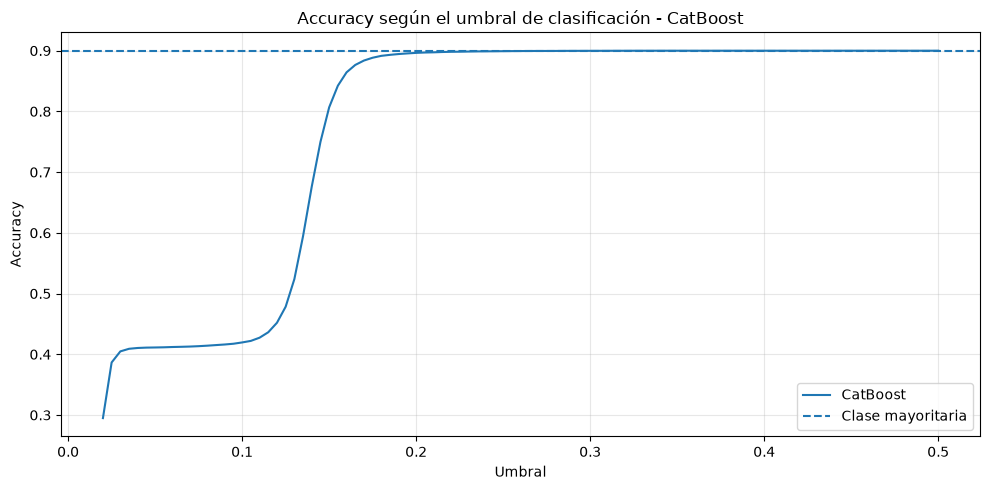

In [38]:
# 6.16. EXPLORACIÓN DE UMBRALES - CATBOOST

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Umbrales que vamos a evaluar
umbrales_catboost = np.arange(0.02, 0.501, 0.005)

resultados_umbrales_catboost = []

for umbral in umbrales_catboost:

    predicciones = (
        probabilidades_catboost >= umbral
    ).astype(int)

    resultados_umbrales_catboost.append({
        "Umbral": round(float(umbral), 3),
        "Accuracy": accuracy_score(y_dev, predicciones),
        "Precision_1": precision_score(
            y_dev, predicciones, zero_division=0
        ),
        "Recall_1": recall_score(
            y_dev, predicciones, zero_division=0
        ),
        "F1_1": f1_score(
            y_dev, predicciones, zero_division=0
        ),
        "Predicciones_1": int(predicciones.sum())
    })

tabla_umbrales_catboost = pd.DataFrame(
    resultados_umbrales_catboost
)

print("MEJORES UMBRALES EXPLORATORIOS DE CATBOOST")

display(
    tabla_umbrales_catboost
    .sort_values("Accuracy", ascending=False)
    .head(10)
    .round(4)
)

# Identificar el umbral exploratorio con mayor Accuracy
mejor_resultado_catboost = tabla_umbrales_catboost.loc[
    tabla_umbrales_catboost["Accuracy"].idxmax()
]

print("\nMejor umbral exploratorio:",
      round(mejor_resultado_catboost["Umbral"], 3))

print("Accuracy exploratorio:",
      round(mejor_resultado_catboost["Accuracy"], 4))

print("Accuracy de referencia:",
      round(y_dev.value_counts(normalize=True).max(), 4))

# Visualización
plt.figure(figsize=(10, 5))

plt.plot(
    tabla_umbrales_catboost["Umbral"],
    tabla_umbrales_catboost["Accuracy"],
    label="CatBoost"
)

plt.axhline(
    y_dev.value_counts(normalize=True).max(),
    linestyle="--",
    label="Clase mayoritaria"
)

plt.title("Accuracy según el umbral de clasificación - CatBoost")
plt.xlabel("Umbral")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [39]:
# 6.17. MODELO XGBOOST - CLASIFICACIÓN BINARIA

from xgboost import XGBClassifier

# Crear modelo XGBoost con preprocesamiento base
modelo_xgboost = Pipeline(steps=[
    ("preprocesamiento", clone(preprocesador_base)),
    ("modelo", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=5,
        reg_lambda=5.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=4,
        tree_method="hist"
    ))
])

# Evaluar mediante validación cruzada agrupada
resultados_xgboost = cross_validate(
    modelo_xgboost,
    X_dev,
    y_dev,
    groups=grupos_dev,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    n_jobs=1
)

accuracy_xgboost = resultados_xgboost["test_accuracy"]
auc_xgboost = resultados_xgboost["test_roc_auc"]

# Registrar resultados
resultados_modelos.append({
    "Modelo": "XGBoost",
    "Preprocesamiento": "Base",
    "Accuracy_promedio": accuracy_xgboost.mean(),
    "Desviacion_estandar": accuracy_xgboost.std(),
    "Accuracy_minimo": accuracy_xgboost.min(),
    "Accuracy_maximo": accuracy_xgboost.max()
})

print("RESULTADOS DE XGBOOST")
print("-" * 45)

for i, (acc, auc) in enumerate(
    zip(accuracy_xgboost, auc_xgboost),
    start=1
):
    print(f"Partición {i}: Accuracy={acc:.4f} | ROC-AUC={auc:.4f}")

print(f"\nAccuracy promedio: {accuracy_xgboost.mean():.4f}")
print(f"ROC-AUC promedio: {auc_xgboost.mean():.4f}")
print(f"Desviación del Accuracy: {accuracy_xgboost.std():.4f}")

print("\nCOMPARACIÓN DE TODOS LOS MODELOS")
display(
    pd.DataFrame(resultados_modelos)
    .sort_values("Accuracy_promedio", ascending=False)
    .round(4)
)


RESULTADOS DE XGBOOST
---------------------------------------------
Partición 1: Accuracy=0.8999 | ROC-AUC=0.6546
Partición 2: Accuracy=0.8999 | ROC-AUC=0.6510
Partición 3: Accuracy=0.8999 | ROC-AUC=0.6496
Partición 4: Accuracy=0.8998 | ROC-AUC=0.6613
Partición 5: Accuracy=0.8999 | ROC-AUC=0.6554

Accuracy promedio: 0.8999
ROC-AUC promedio: 0.6544
Desviación del Accuracy: 0.0000

COMPARACIÓN DE TODOS LOS MODELOS


,Modelo,Preprocesamiento,Accuracy_promedio,Desviacion_estandar,Accuracy_minimo,Accuracy_maximo
0,DummyClassifier,Sin transformación,0.8999,0.0000,0.8998,0.8999
1,Regresión Logística,Base + escalado,0.8999,0.0000,0.8998,0.8999
2,Árbol de Decisión,Base,0.8999,0.0000,0.8998,0.8999
4,Random Forest,Base,0.8999,0.0000,0.8998,0.8999
6,CatBoost,Categorías nativas,0.8999,0.0000,0.8998,0.8999
5,HistGradientBoosting,Base,0.8999,0.0000,0.8998,0.8999
7,XGBoost,Base,0.8999,0.0000,0.8998,0.8999
3,Árbol de Decisión Ampliado,Ingeniería de características,0.8963,0.0011,0.8945,0.8977


In [ ]:
# DIAGNÓSTICO DE GRUPOS CON MAYOR RIESGO          borrar hasta aqui desde xboost

# Utilizamos únicamente el conjunto de desarrollo
diagnostico = X_dev.copy()
diagnostico["riesgo"] = y_dev.to_numpy()

# Crear grupos de edad para explorar patrones
diagnostico["grupo_edad"] = pd.cut(
    diagnostico["edad_meses"],
    bins=[-float("inf"), 0, 6, 12, 18, 24, float("inf")],
    labels=[
        "Edad <= 0",
        "1 a 6 meses",
        "7 a 12 meses",
        "13 a 18 meses",
        "19 a 24 meses",
        "Más de 24 meses"
    ]
)

# Tasas de riesgo según combinaciones observadas
tabla_grupos = (
    diagnostico.groupby(
        ["region", "nivel_educacion_madre", "grupo_edad"],
        observed=True
    )["riesgo"]
    .agg(["size", "sum", "mean"])
    .reset_index()
)

tabla_grupos.columns = [
    "Region", "Educacion_madre", "Grupo_edad",
    "Registros", "Casos_riesgo", "Tasa_riesgo"
]

tabla_grupos["Tasa_riesgo"] *= 100

# Evitar conclusiones a partir de grupos muy pequeños
grupos_suficientes = tabla_grupos[
    tabla_grupos["Registros"] >= 100
]

print("GRUPOS CON MAYORES TASAS DE RIESGO")
display(
    grupos_suficientes.sort_values(
        "Tasa_riesgo", ascending=False
    ).head(20).round(2)
)

print("\nTASA MÁXIMA OBSERVADA (%):")
print(round(grupos_suficientes["Tasa_riesgo"].max(), 2))

print("\nGRUPOS CON RIESGO SUPERIOR AL 50 %:")
print((grupos_suficientes["Tasa_riesgo"] > 50).sum())


GRUPOS CON MAYORES TASAS DE RIESGO


,Region,Educacion_madre,Grupo_edad,Registros,Casos_riesgo,Tasa_riesgo
53,Insular,Primaria,Más de 24 meses,214,37,17.29
92,Sierra,Superior,7 a 12 meses,409,68,16.63
59,Insular,Secundaria,Más de 24 meses,301,50,16.61
74,Sierra,Primaria,7 a 12 meses,1085,179,16.50
58,Insular,Secundaria,19 a 24 meses,1229,202,16.44
25,Costa,Primaria,1 a 6 meses,1082,173,15.99
83,Sierra,Secundaria,Más de 24 meses,278,43,15.47
82,Sierra,Secundaria,19 a 24 meses,1177,181,15.38
67,Insular,Superior,1 a 6 meses,481,73,15.18
80,Sierra,Secundaria,7 a 12 meses,1414,211,14.92



TASA MÁXIMA OBSERVADA (%):
17.29

GRUPOS CON RIESGO SUPERIOR AL 50 %:
0


ANALISIS ANTROPOMETRICO
---------------------------------------------
Registros de desarrollo: 56002
Registros con medidas válidas: 42614

PESO Y TALLA SEGUN EDAD Y RIESGO


,edad_meses,riesgo,cantidad,peso_mediano,talla_mediana
0,0,0,1613,2.992,50.008
1,0,1,192,2.920,49.499
2,1,0,1548,3.279,51.464
3,1,1,178,3.296,51.776
4,2,0,1578,3.625,53.022
5,2,1,190,3.638,53.183
6,3,0,1654,3.919,54.559
7,3,1,189,3.872,54.581
8,4,0,1607,4.177,56.065
9,4,1,182,4.350,55.755


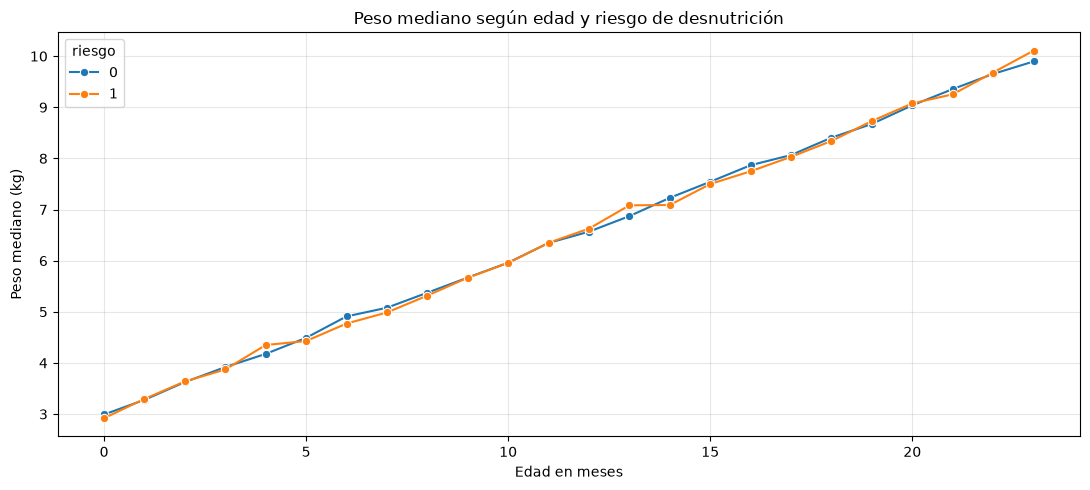

In [41]:
# 6.18. ANALISIS ANTROPOMETRICO

# Crear copia de los datos de desarrollo
datos_antropometricos = X_dev.copy()

# Agregar las etiquetas correspondientes
datos_antropometricos["riesgo"] = y_dev.to_numpy()

# Mantener edades válidas para esta comparación
datos_validos = datos_antropometricos[
    datos_antropometricos["edad_meses"].between(0, 23)
    & (datos_antropometricos["peso_kg"] > 0)
    & (datos_antropometricos["talla_cm"] > 0)
].copy()

# Agrupar por edad y clase
resumen_antropometrico = (
    datos_validos
    .groupby(["edad_meses", "riesgo"])
    .agg(
        cantidad=("peso_kg", "size"),
        peso_mediano=("peso_kg", "median"),
        talla_mediana=("talla_cm", "median")
    )
    .reset_index()
)

print("ANALISIS ANTROPOMETRICO")
print("-" * 45)

print("Registros de desarrollo:", len(X_dev))
print("Registros con medidas válidas:", len(datos_validos))

print("\nPESO Y TALLA SEGUN EDAD Y RIESGO")
display(resumen_antropometrico.head(20).round(3))

# Visualizar peso mediano por edad y clase
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=resumen_antropometrico,
    x="edad_meses",
    y="peso_mediano",
    hue="riesgo",
    marker="o"
)

plt.title("Peso mediano según edad y riesgo de desnutrición")
plt.xlabel("Edad en meses")
plt.ylabel("Peso mediano (kg)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


IMPORTANCIA DE VARIABLES - XGBOOST


,Variable,Importancia_media,Desviacion
2,region,0.1113,0.0059
3,nivel_educacion_madre,0.0388,0.0045
0,edad_meses,0.0183,0.0022
4,peso_kg,0.0042,0.0035
5,talla_cm,0.0011,0.0034
1,sexo,-0.0001,0.0012


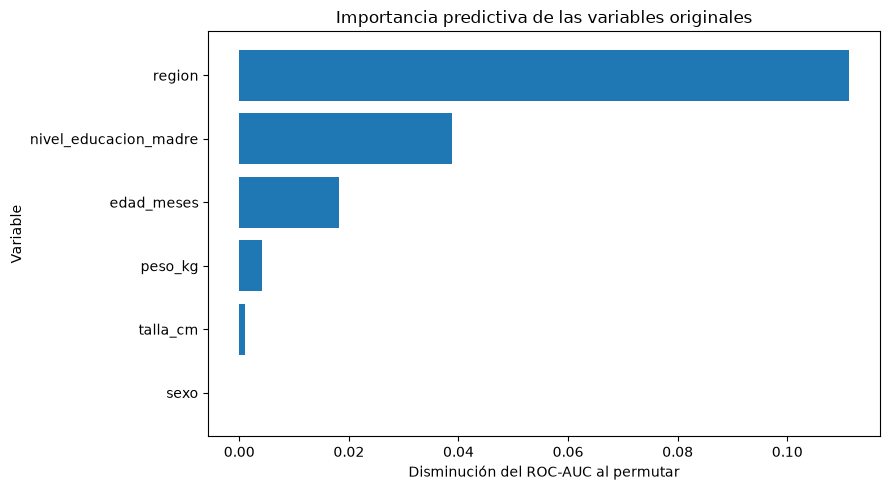

In [42]:
# 6.19. IMPORTANCIA DE VARIABLES CON PERMUTACIÓN

from sklearn.inspection import permutation_importance
from sklearn.base import clone

# Utilizar la primera partición agrupada
indice_entrenamiento, indice_validacion = next(
    cv.split(X_dev, y_dev, groups=grupos_dev)
)

X_ent = X_dev.iloc[indice_entrenamiento]
X_val = X_dev.iloc[indice_validacion]

y_ent = y_dev.iloc[indice_entrenamiento]
y_val = y_dev.iloc[indice_validacion]

# Entrenar XGBoost únicamente con la parte de entrenamiento
modelo_importancia = clone(modelo_xgboost)
modelo_importancia.fit(X_ent, y_ent)

# Calcular importancia en datos no utilizados para el ajuste
importancias = permutation_importance(
    modelo_importancia,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=SEED,
    n_jobs=1
)

tabla_importancias = pd.DataFrame({
    "Variable": X_val.columns,
    "Importancia_media": importancias.importances_mean,
    "Desviacion": importancias.importances_std
}).sort_values(
    "Importancia_media",
    ascending=False
)

print("IMPORTANCIA DE VARIABLES - XGBOOST")
display(tabla_importancias.round(4))

plt.figure(figsize=(9, 5))

plt.barh(
    tabla_importancias["Variable"][::-1],
    tabla_importancias["Importancia_media"][::-1]
)

plt.xlabel("Disminución del ROC-AUC al permutar")
plt.ylabel("Variable")
plt.title("Importancia predictiva de las variables originales")
plt.tight_layout()
plt.show()


In [43]:
# 6.20. OPTIMIZACIÓN DE XGBOOST

from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
from scipy.stats import randint, uniform, loguniform

# Construir las particiones una sola vez
particiones_optimizacion = list(
    cv.split(X_dev, y_dev, groups=grupos_dev)
)

# Parámetros que exploraremos
espacio_parametros = {
    "modelo__n_estimators": randint(150, 601),
    "modelo__max_depth": randint(2, 9),
    "modelo__learning_rate": loguniform(0.02, 0.20),
    "modelo__min_child_weight": randint(1, 16),
    "modelo__subsample": uniform(0.70, 0.30),
    "modelo__colsample_bytree": uniform(0.70, 0.30),
    "modelo__reg_lambda": loguniform(0.1, 20.0)
}

busqueda_xgboost = RandomizedSearchCV(
    estimator=clone(modelo_xgboost),
    param_distributions=espacio_parametros,
    n_iter=12,
    scoring="accuracy",
    cv=particiones_optimizacion,
    random_state=SEED,
    n_jobs=1,
    verbose=1,
    refit=True,
    error_score="raise"
)

print("INICIANDO OPTIMIZACIÓN DE XGBOOST")

busqueda_xgboost.fit(X_dev, y_dev)

print("\nMEJOR ACCURACY DE VALIDACIÓN CRUZADA:")
print(round(busqueda_xgboost.best_score_, 4))

print("\nMEJORES HIPERPARÁMETROS:")
for parametro, valor in busqueda_xgboost.best_params_.items():
    print(parametro, ":", round(valor, 5)
          if isinstance(valor, float) else valor)

print("\nLAS CINCO MEJORES CONFIGURACIONES:")
resultados_busqueda = pd.DataFrame(
    busqueda_xgboost.cv_results_
)

display(
    resultados_busqueda[
        ["rank_test_score", "mean_test_score",
         "std_test_score", "params"]
    ]
    .sort_values("rank_test_score")
    .head(5)
    .round(4)
)

print("\nEl conjunto de reserva no ha sido utilizado.")


INICIANDO OPTIMIZACIÓN DE XGBOOST
Fitting 5 folds for each of 12 candidates, totalling 60 fits

MEJOR ACCURACY DE VALIDACIÓN CRUZADA:
0.8999

MEJORES HIPERPARÁMETROS:
modelo__colsample_bytree : 0.8835
modelo__learning_rate : 0.02033
modelo__max_depth : 2
modelo__min_child_weight : 1
modelo__n_estimators : 208
modelo__reg_lambda : 0.83194
modelo__subsample : 0.714

LAS CINCO MEJORES CONFIGURACIONES:


,rank_test_score,mean_test_score,std_test_score,params
3,1,0.8999,0.0,{'modelo__colsample_bytree': 0.883495948146484...
6,1,0.8999,0.0,{'modelo__colsample_bytree': 0.982660526705455...
5,1,0.8999,0.0,{'modelo__colsample_bytree': 0.877724370658612...
4,1,0.8999,0.0,{'modelo__colsample_bytree': 0.992126655652437...
7,1,0.8999,0.0,{'modelo__colsample_bytree': 0.832045748121880...



El conjunto de reserva no ha sido utilizado.


## 7. Evaluación final del modelo


In [44]:
# 7.1. EVALUACION FINAL EN CONJUNTO RESERVADO

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Modelo previamente seleccionado mediante validación cruzada
modelo_final_evaluacion = busqueda_xgboost.best_estimator_

# Predicciones sobre el conjunto reservado
predicciones_reserva = modelo_final_evaluacion.predict(X_holdout)

# Accuracy independiente
accuracy_final = accuracy_score(
    y_holdout,
    predicciones_reserva
)

# Referencia: predecir siempre la clase 0
predicciones_referencia = np.zeros(len(y_holdout), dtype=int)

accuracy_referencia = accuracy_score(
    y_holdout,
    predicciones_referencia
)

print("EVALUACION FINAL INDEPENDIENTE")
print("-" * 45)

print(f"Accuracy XGBoost: {accuracy_final:.4f}")
print(f"Accuracy referencia: {accuracy_referencia:.4f}")

print("\nMATRIZ DE CONFUSION")
display(
    pd.DataFrame(
        confusion_matrix(
            y_holdout,
            predicciones_reserva,
            labels=[0, 1]
        ),
        index=["Real 0", "Real 1"],
        columns=["Predicho 0", "Predicho 1"]
    )
)

print("\nREPORTE DE CLASIFICACION")
print(
    classification_report(
        y_holdout,
        predicciones_reserva,
        zero_division=0
    )
)

print("\nDIFERENCIA FRENTE A LA REFERENCIA")
print(round(accuracy_final - accuracy_referencia, 4))


EVALUACION FINAL INDEPENDIENTE
---------------------------------------------
Accuracy XGBoost: 0.8998
Accuracy referencia: 0.8998

MATRIZ DE CONFUSION


,Predicho 0,Predicho 1
Real 0,12595,0
Real 1,1403,0



REPORTE DE CLASIFICACION
              precision    recall  f1-score   support

           0       0.90      1.00      0.95     12595
           1       0.00      0.00      0.00      1403

    accuracy                           0.90     13998
   macro avg       0.45      0.50      0.47     13998
weighted avg       0.81      0.90      0.85     13998


DIFERENCIA FRENTE A LA REFERENCIA
0.0


In [45]:
# 7.2. VERIFICACIÓN DE LA PLANTILLA DE KAGGLE

print("COLUMNAS DE LA PLANTILLA:")
print(sample_submission.columns.tolist())

print("\nDIMENSIONES:")
print("Datos de prueba:", X_test.shape)
print("Plantilla:", sample_submission.shape)

print("\nPRIMEROS REGISTROS:")
display(sample_submission.head())

print("\nVERIFICACIONES:")

assert sample_submission.columns.tolist() == [
    "ID",
    "alerta_desnutricion"
], "Error: las columnas no coinciden con la plantilla esperada."

assert len(sample_submission) == len(X_test), \
    "Error: distinta cantidad de registros."

assert sample_submission["ID"].is_unique, \
    "Error: existen ID duplicados."

print("Plantilla verificada correctamente.")
print("Los ID originales deben conservarse.")
print("Todavía no se ha generado ningún envío.")


COLUMNAS DE LA PLANTILLA:
['ID', 'alerta_desnutricion']

DIMENSIONES:
Datos de prueba: (30000, 6)
Plantilla: (30000, 2)

PRIMEROS REGISTROS:


,ID,alerta_desnutricion
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0



VERIFICACIONES:
Plantilla verificada correctamente.
Los ID originales deben conservarse.
Todavía no se ha generado ningún envío.


## 8. Entrenamiento definitivo y generación de predicciones


In [46]:
# 8.1. ENTRENAMIENTO DEFINITIVO Y ARCHIVO DE KAGGLE

from sklearn.base import clone
from pathlib import Path

# Recuperar el modelo seleccionado
modelo_entrega = clone(busqueda_xgboost.best_estimator_)

# Preparar etiquetas
etiquetas_completas = y_train["alerta_desnutricion"]

# Entrenar con todos los datos etiquetados
modelo_entrega.fit(X_train, etiquetas_completas)

# Predecir los datos de prueba
predicciones_test = modelo_entrega.predict(X_test).astype(int)

# Copiar la plantilla para conservar los ID
envio_kaggle = sample_submission.copy()

# Reemplazar únicamente la columna de predicciones
envio_kaggle["alerta_desnutricion"] = predicciones_test

# Verificaciones obligatorias
assert envio_kaggle.columns.equals(sample_submission.columns)
assert envio_kaggle["ID"].equals(sample_submission["ID"])
assert len(envio_kaggle) == len(X_test)
assert envio_kaggle["alerta_desnutricion"].isin([0, 1]).all()
assert envio_kaggle["alerta_desnutricion"].notna().all()

# Guardar archivo
ruta_envio = Path("submission_desnutricion_final.csv")
envio_kaggle.to_csv(ruta_envio, index=False)

print("ARCHIVO GENERADO CORRECTAMENTE")
print("Nombre:", ruta_envio)
print("Registros:", len(envio_kaggle))

print("\nDISTRIBUCIÓN DE PREDICCIONES:")
print(envio_kaggle["alerta_desnutricion"].value_counts())

print("\nPRIMERAS FILAS:")
display(envio_kaggle.head())

print("\nID conservados:", envio_kaggle["ID"].equals(sample_submission["ID"]))
print("Archivo listo para revisión antes del envío.")


ARCHIVO GENERADO CORRECTAMENTE
Nombre: submission_desnutricion_final.csv
Registros: 30000

DISTRIBUCIÓN DE PREDICCIONES:
alerta_desnutricion
0    30000
Name: count, dtype: int64

PRIMERAS FILAS:


,ID,alerta_desnutricion
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0



ID conservados: True
Archivo listo para revisión antes del envío.


## 9. Resultados y conclusiones finales


### 9.1. Resultados obtenidos

Se desarrolló un proyecto de clasificación binaria para predecir el riesgo de desnutrición infantil en Ecuador, utilizando información antropométrica y sociodemográfica de niños menores de dos años.

El conjunto de entrenamiento estuvo conformado por 70.000 registros y seis variables predictoras: edad en meses, sexo, región, nivel educativo de la madre, peso y talla.

Durante el desarrollo se realizaron procesos de análisis exploratorio, evaluación de calidad de datos, ingeniería de características, preprocesamiento, validación cruzada y comparación de diferentes algoritmos de Machine Learning.

Se evaluaron modelos como regresión logística, árboles de decisión, Random Forest, HistGradientBoosting, CatBoost y XGBoost.

Posteriormente, se optimizaron los hiperparámetros de XGBoost mediante RandomizedSearchCV, utilizando cinco particiones de validación cruzada agrupada.

Los resultados principales fueron:

- **Accuracy promedio de validación cruzada:** 89,99 %.
- **Accuracy en el conjunto de reserva:** 89,98 %.
- **Accuracy público obtenido en Kaggle:** 91,13 %.
- **Métrica oficial:** Accuracy.
- **Archivo de entrega:** submission_desnutricion_final.csv.

### 9.2. Interpretación de los resultados

El conjunto de entrenamiento presentó un desbalance considerable entre las clases, con aproximadamente un 90 % de registros correspondientes a niños sin riesgo y un 10 % a niños con riesgo de desnutrición.

Durante las evaluaciones, los modelos obtuvieron resultados cercanos al clasificador de referencia. El modelo final XGBoost predijo la clase mayoritaria para todas las observaciones del conjunto de prueba.

Por tanto, aunque se alcanzó un Accuracy público del 91,13 % en Kaggle, este resultado no demuestra una mejora en la identificación de los casos positivos. La puntuación pública también está sujeta a las características de la muestra evaluada.

### 9.3. Conclusión final

El proyecto permitió aplicar las principales etapas de un proceso de aprendizaje automático supervisado, desde la exploración y preparación de datos hasta la comparación, optimización y evaluación de modelos predictivos.

Se obtuvo una puntuación pública de **0,911254675280 en Kaggle**

Sin embargo, se identificó que el desbalance de clases representa una limitación importante, ya que una elevada exactitud puede coexistir con una capacidad insuficiente para detectar niños en riesgo de desnutrición.

Como oportunidad de mejora, se recomienda investigar nuevas características predictivas, métodos de calibración y estrategias de clasificación que permitan mejorar la detección de la clase minoritaria sin comprometer la generalización del modelo.

Finalmente, se destaca la importancia de utilizar validación independiente, evitar el sobreajuste y diferenciar las puntuaciones públicas de Kaggle del rendimiento definitivo sobre datos no observados.